<a href="https://colab.research.google.com/github/mudassar2224/Machine-Learning/blob/main/08_my_Chapter_Dimensionality_Reduction.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import sys

assert sys.version_info >= (3, 7)

In [ ]:
from packaging import version
import sklearn

assert version.parse(sklearn.__version__) >= version.parse("1.0.1")

In [ ]:
import matplotlib.pyplot as plt

plt.rc('font', size=14)
plt.rc('axes', labelsize=14, titlesize=14)
plt.rc('legend', fontsize=14)
plt.rc('xtick', labelsize=10)
plt.rc('ytick', labelsize=10)

In [ ]:
from pathlib import Path

IMAGES_PATH = Path() / "images" / "dim_reduction"
IMAGES_PATH.mkdir(parents=True, exist_ok=True)

def save_fig(fig_id, tight_layout=True, fig_extension="png", resolution=300):
    path = IMAGES_PATH / f"{fig_id}.{fig_extension}"
    if tight_layout:
        plt.tight_layout()
    plt.savefig(path, format=fig_extension, dpi=resolution)



Let’s break it down step by step so you can **really understand the concept** instead of just reading the theory.

---

# 🌌 The Curse of Dimensionality (Explained Simply)

## 1. Everyday Intuition (2D & 3D worlds)

We humans think in **2D (paper, maps)** or **3D (real world)**.

* In 2D (square), points are pretty evenly spread out.
* In 3D (cube), still okay — you can imagine distance between points.

But in **higher dimensions** (100D, 1000D…), things get **very weird** and **our intuition fails**.

---

## 2. What Happens in High Dimensions?

* **Points move far apart**
  In 2D, two random points are \~0.52 units apart on average.
  In 3D, \~0.66 apart.
  In 1,000,000D, the average distance jumps to **408.25 units** 🤯
  ➝ Meaning: points become very far away from each other.

* **Most points are near the border**
  In 2D (a square), very few points are close to the edges.
  In 10,000D, almost **all points are extremely close to the “edges”**.
  ➝ So, data becomes sparse and clustered near borders.

---

## 3. Why is This a Problem in Machine Learning?

* **Nearest Neighbor Search becomes unreliable**
  If every point is equally far from every other point, “closeness” doesn’t mean much.
  Example: KNN classifier struggles because nearest neighbors aren’t truly *close*.

* **Overfitting risk increases**
  With more dimensions, models can separate data too easily (because space is empty).
  This separation may not generalize → poor performance on test data.

* **Need exponential training data**
  To properly fill a 100D space, you would need more training points than atoms in the universe 😅. Not possible.

---

## 4. How to Build Intuition?

Think of a **cube analogy**:

* A 1D cube = a line (length 1).
* A 2D cube = a square (1×1).
* A 3D cube = a cube (1×1×1).
* A 10D cube = ??? Hard to visualize, but still mathematically valid.

Now, if you place random points:

* In 2D → points cluster in the middle.
* In 1000D → points *run away* to the edges, and they’re all far apart.

👉 So, “high dimensions” = **lots of empty space + far apart data**.

---

## 5. Why Dimensionality Reduction Helps

* If your data really only depends on fewer factors (e.g., digits in MNIST depend on \~100 features instead of 784 pixels),
  then **projecting down to fewer dimensions** keeps the important structure while removing noise.
* Methods like **PCA, Kernel PCA, LLE** help find these **low-dimensional manifolds** inside high-dimensional space.

---

✅ **Summary in One Line:**
The Curse of Dimensionality means that as dimensions grow, data becomes sparse, distances lose meaning, and ML models struggle — that’s why we reduce dimensions.

---



# **Projection**

Perfect 👌 you’re now at the **“Main Approaches for Dimensionality Reduction”** section — Projection vs. Manifold Learning. Let’s **simplify this theory into intuition + examples** so you can **really understand projection**.

---

# 🔹 What is Projection?

👉 **Definition:**
Projection = take high-dimensional data and **“drop” it onto a lower-dimensional flat surface (subspace)**, usually a line, plane, or hyperplane.

Think of shining a flashlight:

* You have a 3D object (say, a cube).
* Its **shadow** on a 2D wall is the **projection**.
* The shadow loses one dimension but keeps some structure.

---

# 🔹 Why Projection Works

In real datasets:

* Not all features are important.
* Many features are **correlated** (e.g., height and arm length).
* So, the data doesn’t really use all dimensions — it lies close to a **subspace** (flat surface inside higher-dimensional space).

📌 Example:

* A 3D dataset where points lie close to a flat plane.
* Projecting onto that plane reduces it to 2D without losing much information.
* That’s exactly what the book’s **Figure 8-2 & 8-3** show.

---

# 🔹 Where Projection Fails

Projection assumes data lies near a **flat subspace**.
But real-world data may lie on a **curved surface (manifold)**.

📌 Example: **Swiss Roll dataset**

* Looks like a rolled-up 2D sheet in 3D space.
* If you simply drop the z-axis (projection), layers of the roll overlap (bad!).
* Instead, you’d want to **“unroll”** the manifold → this is **Manifold Learning**.

---

# 🔹 When to Use Projection

✅ Good when:

* Data is “flat-ish” (linear subspace).
* Features are correlated → projection removes redundancy.
* You just want a **simpler dataset** (e.g., for faster training).

❌ Not good when:

* Data is highly **nonlinear** (like Swiss roll).
* Projection squashes different regions together → information is lost.

---

# 🔹 Key Concepts from This Theory

1. **High-D data often lies on a low-D subspace**
   (e.g., 3D points close to a 2D plane).

2. **Projection = drop points onto that subspace**
   (like shadows on a wall).

3. **Result = new features (z1, z2, …)**
   Coordinates in the subspace.

4. **Limitation**: If data lies on a **curved manifold**, projection mixes up different layers → wrong representation.

---

# 🌟 Intuition Recap in One Line:

Projection is like taking a **shadow of your data** on a lower-dimensional surface: simple and fast, but it only works well if the data really lies close to a flat plane (linear subspace).
---


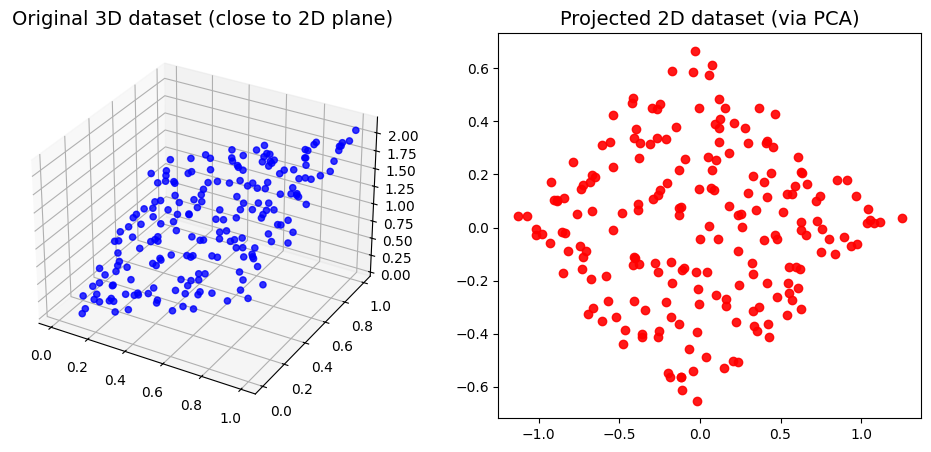

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA
from  sklearn.datasets import fetch_openml
from sklearn.manifold import LocallyLinearEmbedding
np.random.seed(42)
m=200
X=np.random.rand(m ,3)
X[:, 2]=X[:, 0]+X[:, 1]+np.random.normal(0, 0.05, m)
pca=PCA(n_components=2)
X2D=pca.fit_transform(X)
fig=plt.figure(figsize=(12, 5))
ax=fig.add_subplot(121, projection="3d")
ax.scatter(X[:, 0], X[:, 1], X[:,2], c="blue",  alpha=0.8)
ax.set_title("Original 3D dataset (close to 2D plane)")
ax2=fig.add_subplot(122)
ax2.scatter(X2D[:, 0], X2D[:, 1], c="red", alpha=0.9)

ax2.set_title("Projected 2D dataset (via PCA)")
plt.show()

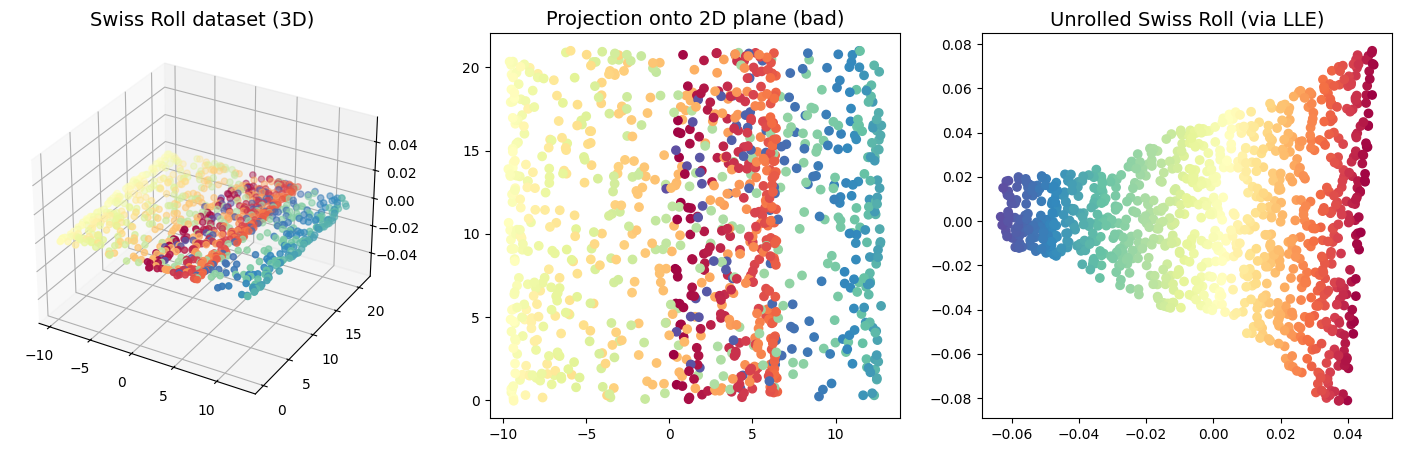

In [ ]:
from sklearn.datasets import make_swiss_roll
X_swiss, t=make_swiss_roll(n_samples=1000,

                           noise=0.1,
                           random_state=42)
X_proj=X_swiss[:, [0,1]]
lle=LocallyLinearEmbedding(
    n_neighbors=12,
    n_components=2,
    random_state=42)
X_unrolled=lle.fit_transform(X_swiss)
fig=plt.figure(figsize=(18, 5))
ax=fig.add_subplot(131,projection="3d")

ax.scatter(X_swiss[:, 0], X_swiss[:, 1], c=t, cmap=plt.cm.Spectral)
ax.set_title("Swiss Roll dataset (3D)")
ax=fig.add_subplot(132)
ax.scatter(X_proj[: ,0],
           X_proj[: ,1],
          c=t,
           cmap=plt.cm.Spectral
           )

ax.set_title("Projection onto 2D plane (bad)")
ax=fig.add_subplot(133)
ax.scatter(
    X_unrolled[:, 0],
    X_unrolled[:, 1],
    c=t,
    cmap=plt.cm.Spectral
)
ax.set_title("Unrolled Swiss Roll (via LLE)")

plt.show()

In [ ]:

ax = fig.add_subplot(131, projection="3d")
ax.scatter(X_swiss[:, 0], X_swiss[:, 1], X_swiss[:, 2], c=t, cmap=plt.cm.Spectral)
ax.set_title("Swiss Roll dataset (3D)")

# Plot projection (bad: layers squashed)
ax2 = fig.add_subplot(132)
ax2.scatter(X_proj[:, 0], X_proj[:, 1], c=t, cmap=plt.cm.Spectral)
ax2.set_title("Projection onto 2D plane (bad)")

# Plot unrolled (good: manifold learning)
ax3 = fig.add_subplot(133)
ax3.scatter(X_unrolled[:, 0], X_unrolled[:, 1], c=t, cmap=plt.cm.Spectral)
ax3.set_title("Unrolled Swiss Roll (via LLE)")

plt.show()


#  **Manifolds**

Perfect question 🙌 You’re at the **core idea** of Chapter 8: **Manifold Learning**.
Let’s break it down step by step so it’s easy to digest.

---

## 🔑 1. What is a Manifold?

* A **d-dimensional manifold** is like a flat sheet that can be **bent or curved** inside a higher-dimensional space.
* Example:

  * A line = **1D manifold** inside 2D or 3D space.
  * A surface (paper, Swiss roll) = **2D manifold** inside 3D.
* Locally (zoom in), the manifold looks like a flat hyperplane, but globally it may curve.

---

## 🔑 2. Manifold Learning = Finding the “Unrolled” Space

* Real-world data (like images, audio, text) may have **many features (high-dim)**.
* But they usually **lie near a lower-dimensional manifold**.

  * Example: MNIST images are 784-dimensional (28×28 pixels) but digits are not random → they live in a lower-d space (say 30–50 dimensions).
* Manifold learning tries to **unroll** the data into this smaller dimension **without losing the important structure**.

---

## 🔑 3. Why do we assume the Manifold Hypothesis?

* Because **most high-dimensional data is highly structured**:

  * Handwritten digits → constrained by shapes, connected lines, centering.
  * Faces → constrained by symmetry, eyes, nose positions.
  * Speech → constrained by human vocal system.
* If data were truly random in all dimensions, it would be impossible to learn patterns.

---

## 🔑 4. Where & Why Use It?

* **Where:**

  * High-dimensional structured datasets (images, text embeddings, speech, genetics).
  * Visualization (reducing from 100D → 2D/3D to plot).
  * Preprocessing before machine learning (to remove noise & redundancy).

* **Why:**

  * Speed up training (fewer dimensions = faster algorithms).
  * Reduce noise (remove irrelevant features).
  * Sometimes → simpler decision boundaries.

---

## 🔑 5. But Be Careful (the catch!)

* Reducing dimensions does **not always** make tasks easier.
* Example from the book (Fig. 8-6):

  * Case 1: In 3D, the decision boundary is very complex, but in 2D (unrolled manifold) it becomes simple (a straight line). ✅ Good.
  * Case 2: In 3D, the decision boundary is simple (a plane), but in 2D (manifold) it becomes complicated. ❌ Bad.

So, dimensionality reduction = **tool for speed & visualization**, not guaranteed to improve accuracy.

---

## 🎯 How to Understand in Simple Words

Think of **rolling up a paper**:

* The paper is 2D, but rolled into 3D.
* If you want to draw a line separating colors:

  * In rolled form → messy.
  * In unrolled form → straight & easy.

That’s **manifold learning**: find the **“real” flat version** of data hidden in higher dimensions.

---

✅ Summary:

* **Manifold = hidden lower-dimensional structure inside high-dimensional data.**
* **Use:** when data has structure (images, speech, etc.), for visualization & faster learning.
* **Why:** because data usually doesn’t use all possible dimensions → it lies on a lower-dimensional manifold.
* **Caution:** may not always simplify the ML task.

---




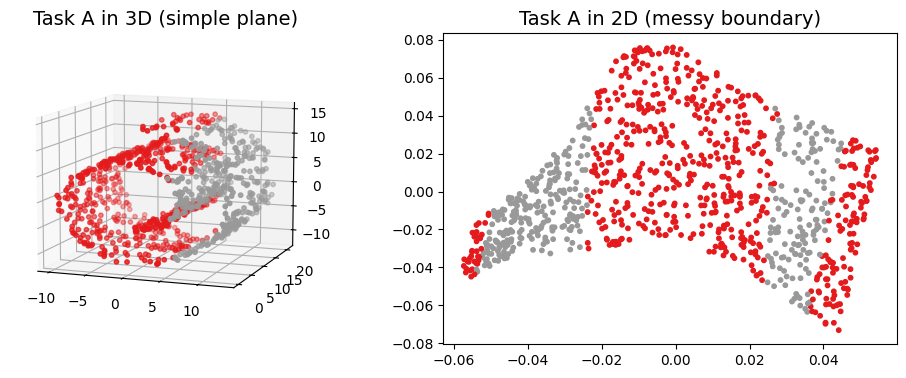

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import make_swiss_roll
from sklearn.manifold import LocallyLinearEmbedding
X, t=make_swiss_roll(
    n_samples=1000,
    noise=0.2,
    random_state=42

)
y_a=X[:, 0]>5

fig = plt.figure(figsize=(10,4))
# 3D view
ax=fig.add_subplot(121, projection="3d")
ax.view_init(10, -70)
ax.scatter(X[:, 0], X[:, 1], X[:, 2], c=y_a, cmap="Set1", s=10)
ax.set_title("Task A in 3D (simple plane)")

# 2D unrolled with  LLE
X_unrolled=LocallyLinearEmbedding(
    n_components=2,

    n_neighbors=12,
    random_state=42


).fit_transform(X)
ax2=fig.add_subplot(122)
ax2.scatter(X_unrolled[:, 0], X_unrolled[:, 1],c=y_a, cmap="Set1", s=10 )
ax2.set_title("Task A in 2D (messy boundary)")

plt.tight_layout()
plt.show()

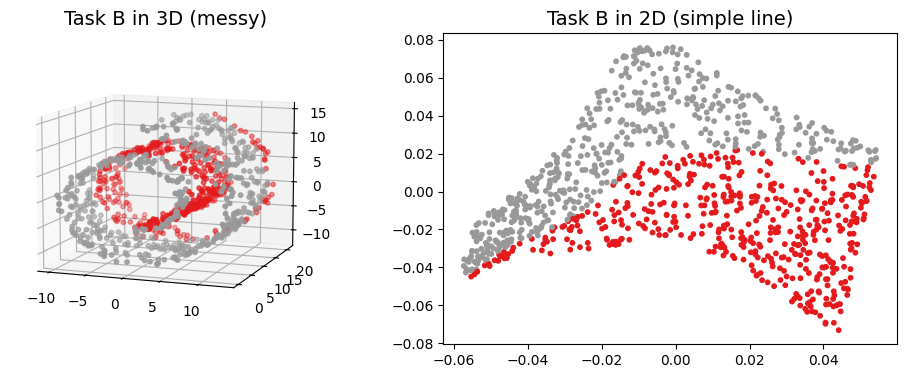

In [ ]:
y_b=2*(t-4)> X[:, 1]
fig=plt.figure(figsize=(10, 4))
ax=fig.add_subplot(121, projection="3d")
ax.view_init(10, -70)
ax.scatter(X[:, 0], X[:, 1], X[:, 2], c=y_b, cmap="Set1", s=10)
ax.set_title("Task B in 3D (messy)")
ax2=fig.add_subplot(122)
ax2.scatter(X_unrolled[:, 0], X_unrolled[:, 1], c=y_b, cmap="Set1", s=10)
ax2.set_title("Task B in 2D (simple line)")
plt.tight_layout()
plt.show()

# PCA

Great question 👍 Let’s break down **PCA (Principal Component Analysis)** in a simple and intuitive way so you really understand it:

---

## 🔹 What is PCA?

PCA is a **dimensionality reduction technique**.
It finds new **axes (directions)** in the data that capture the most **variation (spread)**.

* Imagine your data points are clouds of dots in space.
* PCA rotates and repositions the coordinate system so that:

  * The **first axis (PC1)** captures the largest spread of the data.
  * The **second axis (PC2)** captures the second largest spread (perpendicular to PC1).
  * And so on…

In short: PCA = “find the directions where data varies the most.”

---

## 🔹 Why use PCA?

Because high-dimensional data often has:

* **Redundancy** (many features are correlated).
* **Noise** (random variations not useful for learning).
* **Computational cost** (harder to train models with 100s of features).

PCA helps by:
✅ Compressing the data into fewer dimensions.
✅ Keeping the most important information (variance).
✅ Making visualization possible (e.g., 2D scatterplot of high-dimensional data).
✅ Speeding up ML training while reducing overfitting.

---

## 🔹 Where is PCA used?

1. **Data visualization** – e.g., MNIST digits (784 pixels → 2D with PCA for plotting).
2. **Noise reduction** – remove small-variance components that are just noise.
3. **Preprocessing for ML** – simplify features before feeding into algorithms like clustering or regression.
4. **Compression** – reduce storage needs (e.g., images).

---

## 🔹 How to Understand PCA (with intuition)

Think of PCA like **finding the best camera angle** to take a photo of your data:

* If you pick a bad angle (dotted line in Figure 8-7), the points collapse into a short line → you lose info.
* If you pick the best angle (solid line), the projection still spreads the points apart → maximum information is preserved.
* Mathematically, this “best angle” is the **direction with maximum variance**.

Another way:
PCA minimizes the **distance between original points and their projection**.
That’s why it’s also called **finding the hyperplane of closest fit**.

---

✅ Summary in one line:
**PCA projects data into fewer dimensions while keeping as much variability (information) as possible.**

---




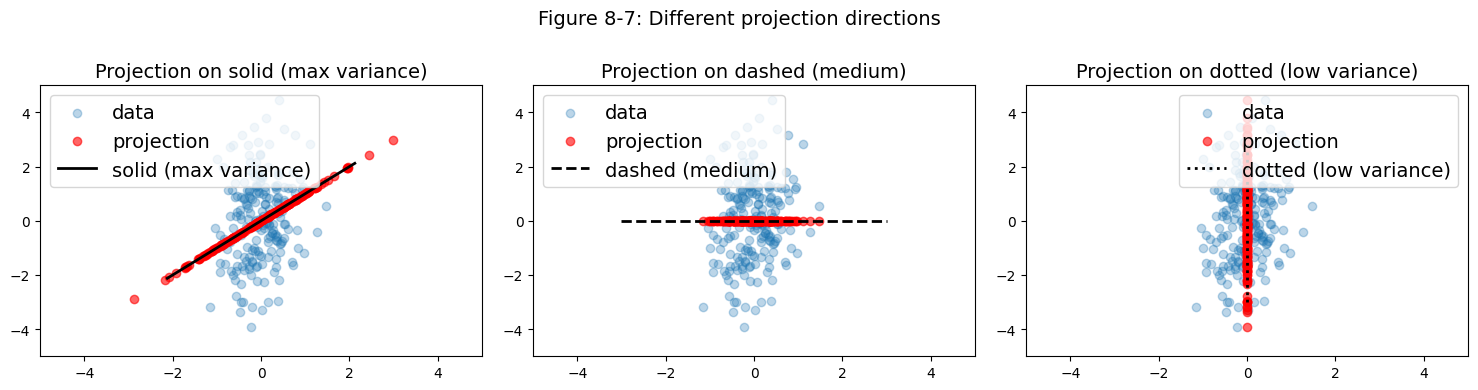

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# 1. Generate 2D dataset (elongated cloud)
np.random.seed(42)
X = np.dot(np.random.randn(2, 2), np.random.randn(2, 200)).T

# 2. Candidate projection directions (unit vectors)
axes = {
    "solid (max variance)": np.array([1, 1]) / np.sqrt(2),     # diagonal (best axis)
    "dashed (medium)": np.array([1, 0]),                       # x-axis
    "dotted (low variance)": np.array([0, 1])                  # y-axis
}

# 3. Function to project onto an axis
def project(X, axis):
    return np.outer(X @ axis, axis)

# 4. Plot original + projections
fig, axes_plot = plt.subplots(1, 3, figsize=(15, 4))

styles = ["-", "--", ":"]
for ax, (style, (label, direction)) in zip(axes_plot, zip(styles, axes.items())):
    ax.scatter(X[:, 0], X[:, 1], alpha=0.3, label="data")

    # projection
    X_proj = project(X, direction)
    ax.scatter(X_proj[:, 0], X_proj[:, 1], c="red", alpha=0.6, label="projection")

    # show axis line
    ax.plot([-3*direction[0], 3*direction[0]],
            [-3*direction[1], 3*direction[1]],
            style, c="black", lw=2, label=f"{label}")

    ax.set_title(f"Projection on {label}")
    ax.set_xlim(-5, 5)
    ax.set_ylim(-5, 5)
    ax.legend()

plt.suptitle("Figure 8-7: Different projection directions", fontsize=14)
plt.tight_layout()
plt.show()


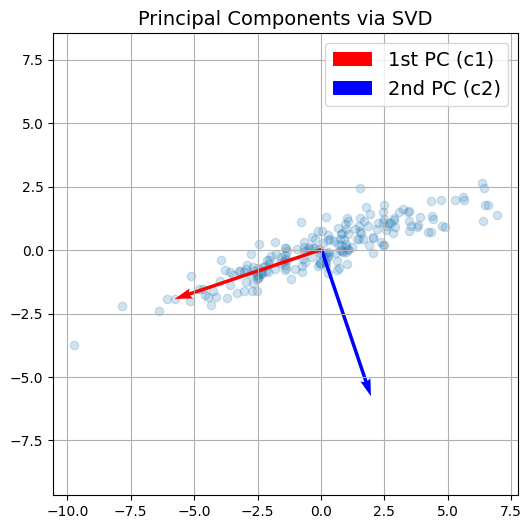

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# 1. Create 2D dataset (elongated cloud)
np.random.seed(42)
X = np.random.randn(200, 2) @ [[3, 1], [0, 0.5]]  # stretched + rotated

# 2. Center the data (very important!)
X_centered = X - X.mean(axis=0)

# 3. SVD decomposition
U, s, Vt = np.linalg.svd(X_centered)

# Principal components
c1 = Vt.T[:, 0]  # 1st PC
c2 = Vt.T[:, 1]  # 2nd PC

# 4. Plot
plt.figure(figsize=(6, 6))
plt.scatter(X[:, 0], X[:, 1], alpha=0.2)

# mean
mean = X.mean(axis=0)

# draw PCs
plt.quiver(*mean, *c1, color='r', scale=3, label="1st PC (c1)")
plt.quiver(*mean, *c2, color='b', scale=3, label="2nd PC (c2)")

plt.axis("equal")
plt.grid()
plt.legend()
plt.title("Principal Components via SVD")
plt.show()


# **PCA Components**

Great question 👍 Let’s carefully unpack this step by step.

---

## 1. **What PCA is doing**

PCA looks for **directions (axes)** in your data that capture the **most variance**:

* **1st PC (Principal Component)** → direction where the data varies the most.
* **2nd PC** → orthogonal (at 90°) to the first, capturing the largest remaining variance.
* Continue for as many dimensions as your data has.

So PCA basically rotates your coordinate system to align with the “natural spread” of your data.
That’s why in **Figure 8-7**:

* The **solid line** (1st PC, $c_1$) = maximum variance axis.
* The **dotted line** (2nd PC, $c_2$) = orthogonal leftover variance axis.

---

## 2. **How PCA finds these directions**

It uses a powerful tool: **Singular Value Decomposition (SVD)**.

If your dataset is a matrix $X$ (rows = samples, columns = features), then:

$$
X = U \, \Sigma \, V^T
$$

* $U$ → tells you about rotations in data space.
* $\Sigma$ → diagonal matrix with “singular values” (related to variance magnitude).
* $V^T$ → contains the **principal components (directions)**.

So:
👉 **Columns of $V$** = the PCs you’re looking for.

---

## 3. **Step-by-step with code**

Here’s a **minimal demo** (very close to the book’s code):

```python
import numpy as np
import matplotlib.pyplot as plt

# 1. Create 2D dataset (elongated cloud)
np.random.seed(42)
X = np.random.randn(200, 2) @ [[3, 1], [0, 0.5]]  # stretched + rotated

# 2. Center the data (very important!)
X_centered = X - X.mean(axis=0)

# 3. SVD decomposition
U, s, Vt = np.linalg.svd(X_centered)

# Principal components
c1 = Vt.T[:, 0]  # 1st PC
c2 = Vt.T[:, 1]  # 2nd PC

# 4. Plot
plt.figure(figsize=(6, 6))
plt.scatter(X[:, 0], X[:, 1], alpha=0.2)

# mean
mean = X.mean(axis=0)

# draw PCs
plt.quiver(*mean, *c1, color='r', scale=3, label="1st PC (c1)")
plt.quiver(*mean, *c2, color='b', scale=3, label="2nd PC (c2)")

plt.axis("equal")
plt.grid()
plt.legend()
plt.title("Principal Components via SVD")
plt.show()
```

---

## 4. **What happens here**

* The **red arrow** = $c_1$ (largest variance direction).
* The **blue arrow** = $c_2$ (orthogonal, leftover variance).
* Together, they define a **new coordinate system** that best describes your data.

---

## 5. **Why center the data?**

If the data is not centered, PCA might mistake the mean offset as “variance.”
So before doing SVD, always do:

$$
X_{centered} = X - \text{mean}(X)
$$

Scikit-Learn’s `PCA` automatically does this for you.

---

✨ In short:
PCA = rotate axes → align with variance → order by importance.
SVD = the mathematical trick that finds those axes.

---


In [ ]:
import numpy as np
X_centered=X-X.mean(axis=0)
U, s,Vt=np.linalg.svd(X_centered)
c1=Vt[0]
c2=Vt[1]


In [ ]:
# extra code – shows how to construct Σ from s
m, n = X.shape
Σ = np.zeros_like(X_centered)
Σ[:n, :n] = np.diag(s)
assert np.allclose(X_centered, U @ Σ @ Vt)

# Projecting down to d Dimensions

Perfect 👌 let’s unpack this idea step by step.

---

## 1. **What we want**

* We have a dataset in high dimensions (say 3D).
* We want to **reduce it to fewer dimensions** (say 2D), but without losing much information.

👉 PCA gives us the **best hyperplane** for projection, defined by the **top $d$ principal components**.

---

## 2. **How the projection works**

1. Compute PCA → get matrix $V$ (principal components).

   * Columns of $V$ = directions of variance (unit vectors).

2. Select the first $d$ PCs → form a matrix $W_d$.

   * Example: If $d=2$, keep the first two columns of $V$.

3. Project original centered dataset $X_{centered}$ onto this new basis:

$$
X_{proj} = X_{centered} \cdot W_d
$$

This multiplication rotates and flattens the data into the new space.

---

## 3. **Code example**

Here’s a working demo of **Equation 8-2**:

```python
import numpy as np
import matplotlib.pyplot as plt

# 1. Create a 3D dataset
np.random.seed(42)
X = np.random.randn(200, 3) @ [[0.5, 0.2, 0.1],
                               [0.4, 0.8, 0.3],
                               [0.2, 0.3, 0.9]]

# 2. Center the data
X_centered = X - X.mean(axis=0)

# 3. SVD (to find PCs)
U, s, Vt = np.linalg.svd(X_centered)

# 4. Take first 2 PCs (matrix W2)
W2 = Vt.T[:, :2]

# 5. Project data onto 2D plane
X2D = X_centered.dot(W2)

# 6. Plot
plt.figure(figsize=(6, 6))
plt.scatter(X2D[:, 0], X2D[:, 1], alpha=0.5)
plt.xlabel("1st principal component")
plt.ylabel("2nd principal component")
plt.title("Projection onto 2D plane via PCA")
plt.grid(True)
plt.show()
```

---

## 4. **What happens**

* The 3D dataset is **flattened onto 2D**, but in the “smartest” way:

  * **Keeps maximum variance**
  * **Loses minimal info**
* The result still looks like the original data, just compressed.

---

## 5. **Why this matters**

* If you naively dropped one feature (say just ignore z-axis), you might lose important structure.
* PCA chooses the **best new axes** automatically.

---

⚡ So in short:

* **Compute SVD** → get PCs.
* **Pick top d PCs** → form $W_d$.
* **Multiply** → project dataset into $d$-dimensional space.

---



In [ ]:
W2 = Vt[:2].T
X2D = X_centered @ W2

 # **Using ScikitLearn**

In [ ]:
from sklearn.decomposition import PCA

pca=PCA(n_components=2)
X2D=pca.fit_transform(X)

In [ ]:
pca.components_

array([[ 0.94759401,  0.31947705],
       [-0.31947705,  0.94759401]])

 # **Explained   Variance Ratio:**

Perfect, you’ve reached the **most important intuition** about PCA: not only does it **find directions (principal components)**, but it also tells you **how much information (variance) each direction captures**.

Let’s break it down step by step:

---

## 1. Principal Components = New Axes

When PCA runs, it finds **new axes (directions)** in which the data is most spread out:

* 1st PC → direction with **maximum variance**
* 2nd PC → orthogonal direction with the **next highest variance**
* … and so on.

So instead of the original axes (x1, x2, x3 …), PCA gives you new axes (PC1, PC2, PC3 …).

---

## 2. Explained Variance Ratio = “Importance” of Each PC

The **explained variance ratio** tells you:
👉 *What fraction of the total spread (variance) of the data is captured by each principal component.*

Example from your output:

```python
pca.explained_variance_ratio_
# array([0.84248607, 0.14631839])
```

* **PC1 captures 84.2%** of the variance.
* **PC2 captures 14.6%** of the variance.
* **PC3 would capture only \~1.2%** (since 100 − 84.2 − 14.6 ≈ 1.2).

This means:

* If you keep **just PC1**, you already capture \~84% of the information.
* If you keep **PC1 + PC2**, you capture \~99% of the information.
* Keeping PC3 doesn’t add much—it mostly looks like noise.

---

## 3. Why is This Useful?

* You can **reduce dimensions** (say, from 100D → 2D) while keeping **most of the info**.
* It helps in **compression** (less storage).
* It removes **noise** (since small-variance PCs often correspond to random fluctuations).
* It speeds up ML models without losing accuracy.

---

## 4. Visual Analogy

Imagine your dataset is a **cloud of points in 3D**:

* Most of the cloud’s spread is along a diagonal line → that’s PC1.
* There’s some spread sideways → that’s PC2.
* Very little spread in the remaining direction → that’s PC3 (almost negligible).

Projecting onto PC1 + PC2 gives you almost the whole shape of the cloud in **2D instead of 3D**.

---

✅ So the **explained\_variance\_ratio\_** is basically an **“information score”** of each principal component.
You keep the top ones until you cover \~95% or \~99% of variance, depending on your task.

---

In [ ]:
pca.explained_variance_ratio_

array([0.97767804, 0.02232196])

In [ ]:
pca.explained_variance_ratio_.sum()

np.float64(1.0)

# **Chossing Right Number of dimensions**


---

## 1. The Problem

When we apply PCA, we must decide:
👉 *How many principal components (PCs) should I keep?*

* If you keep **too few PCs**, you lose too much information (bad).
* If you keep **too many PCs**, you don’t reduce dimensionality much (also bad, defeats the purpose).

So we need a **systematic way** to choose the “right” number of dimensions.

---

## 2. The Key Idea = Preserve Most Variance

* PCA orders components by **variance captured** (PC1 > PC2 > PC3 …).
* So we want to keep enough PCs to **cover most of the variance**, but not all (since some variance is just noise).

Common thresholds:

* **95% variance** → good balance (standard choice in ML).
* **99% variance** → safer but keeps more dimensions.
* **90% variance** → aggressive reduction, but faster.

---

## 3. Two Ways to Choose

### (A) **Variance threshold method**

```python
pca = PCA()
pca.fit(X_train)

cumsum = np.cumsum(pca.explained_variance_ratio_)  # cumulative sum
d = np.argmax(cumsum >= 0.95) + 1  # minimum d where 95% variance is reached
```

* `cumsum` shows how variance adds up as we include more PCs.
* `d` is the smallest number of PCs that explain at least 95% of variance.
* Example: If `d=100`, it means keeping 100 PCs preserves 95% of the dataset’s information.

Then:

```python
pca = PCA(n_components=d)
X_reduced = pca.fit_transform(X_train)
```

---

### (B) **Direct ratio method**

Instead of computing `d` yourself, Scikit-Learn can do it directly:

```python
pca = PCA(n_components=0.95)
X_reduced = pca.fit_transform(X_train)
```

✅ This automatically chooses the minimum number of components that preserve 95% variance.

---

## 4. The Elbow Method (Visual Way)

* Plot cumulative explained variance (`cumsum`) vs. number of components.
* The curve rises steeply at first, then flattens.
* The **“elbow point”** (where curve bends) is the best tradeoff.
* That’s the **intrinsic dimensionality** of your dataset.

Example (like Figure 8-8 in the book):

```
Explained Variance (%)
|
|        *****
|      ***     
|   ***        
| **           
|*             
+-----------------------> # of components
```

* Keep PCs up to the elbow point.
* After that, extra components don’t add much useful info.

---

## 5. Intuition

Think of PCA like **compressing a video**:

* The first few PCs capture the **main structure** (sharp picture).
* Later PCs add only tiny details or noise.
* By cutting after \~95%, you keep almost all the quality but save a lot of space.

---

✅ So in practice:

* For **machine learning** → keep enough PCs to capture 95%+ variance.
* For **visualization** → just reduce to 2D or 3D (even if variance <95%).

---


In [ ]:
from sklearn.datasets import fetch_openml
mnist=fetch_openml("mnist_784", as_frame=False, parser="auto")
X_train, y_train=mnist.data[:60_000], mnist.target[:60_000]
X_test, y_test=mnist.data[60_000:], mnist.target[60_000:]
pca=PCA()
pca.fit(X_train)
cumsum=np.cumsum(pca.explained_variance_ratio_)
d=np.argmax(cumsum>=0.95)+1


In [ ]:
d

np.int64(154)

In [ ]:
pca=PCA(n_components=0.95)
X_reduced=pca.fit_transform(X_train)

In [ ]:
pca.n_components

0.95

In [ ]:
pca.n_components_

np.int64(154)

In [ ]:
pca.explained_variance_ratio_

array([0.09704664, 0.07095924, 0.06169089, 0.05389419, 0.04868797,
       0.04312231, 0.0327193 , 0.02883895, 0.02762029, 0.02357001,
       0.0210919 , 0.02022991, 0.01715818, 0.01692111, 0.01578641,
       0.01482953, 0.01324561, 0.01276897, 0.01187263, 0.01152684,
       0.01066166, 0.01006713, 0.00953573, 0.00912544, 0.00883405,
       0.00839319, 0.00812579, 0.00786366, 0.00744733, 0.00690859,
       0.00658094, 0.00648148, 0.00602615, 0.00586582, 0.00570021,
       0.00543628, 0.00505786, 0.00487859, 0.00481429, 0.00472266,
       0.00456747, 0.00444836, 0.00418501, 0.00398215, 0.00384975,
       0.00375103, 0.00362009, 0.00351591, 0.00340058, 0.00321874,
       0.00319017, 0.00312805, 0.00295983, 0.00288955, 0.0028413 ,
       0.00271436, 0.00269521, 0.00258473, 0.00253771, 0.00244781,
       0.00240506, 0.00239263, 0.00230408, 0.00221532, 0.00213721,
       0.00207225, 0.00203043, 0.00196783, 0.00192853, 0.00188632,
       0.00186977, 0.00181083, 0.00177562, 0.00174898, 0.00165

In [ ]:
pca.explained_variance_ratio_.sum()

np.float64(0.9501960192613031)

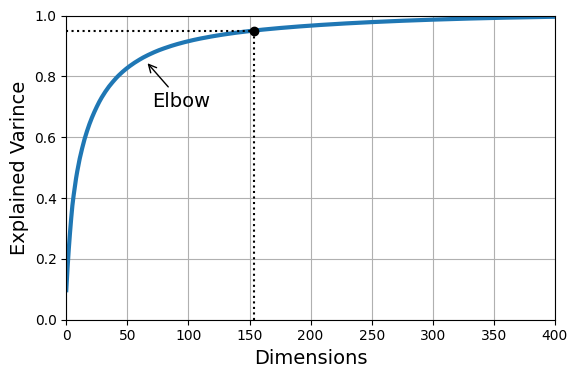

In [ ]:
plt.figure(figsize=(6,4))
plt.plot(cumsum, linewidth=3)
plt.axis([0, 400, 0,1]
         )
plt.xlabel("Dimensions")
plt.ylabel("Explained Varince")
plt.plot([d,d], [0, 0.95], "k:")
plt.plot([0, d], [0.95, 0.95], "k:")
plt.plot(d, 0.95, "ko")
plt.annotate("Elbow", xy=(65, 0.85), xytext=(70, 0.7),
             arrowprops=dict(arrowstyle="->"))

plt.grid(True)
save_fig("explained_variance_plot")
plt.show()


In [ ]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import RandomizedSearchCV
from sklearn.pipeline import  make_pipeline
clf=make_pipeline(
    PCA(random_state=42),
    RandomForestClassifier(random_state=42)

)
param_distrib={
    "pca__n_components":np.arange(10,80),
    "randomforestclassifier__n_estimators":np.arange(50, 500)

}

rnd_search=RandomizedSearchCV(clf, param_distrib,
                               n_iter=10,
                               cv=3
                               )
rnd_search.fit(X_train[:1000], y_train[:1000])

RandomizedSearchCV(cv=3,
                   estimator=Pipeline(steps=[('pca', PCA(random_state=42)),
                                             ('randomforestclassifier',
                                              RandomForestClassifier(random_state=42))]),
                   param_distributions={'pca__n_components': array([10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26,
       27, 28, 29, 30, 31, 32, 33, 34, 35, 36, 37, 38, 39, 40, 41, 42, 43,
       44, 45, 46, 47, 48, 49, 50, 51, 52, 53, 54, 55, 56, 57, 58, 59, 60,
       6...
       401, 402, 403, 404, 405, 406, 407, 408, 409, 410, 411, 412, 413,
       414, 415, 416, 417, 418, 419, 420, 421, 422, 423, 424, 425, 426,
       427, 428, 429, 430, 431, 432, 433, 434, 435, 436, 437, 438, 439,
       440, 441, 442, 443, 444, 445, 446, 447, 448, 449, 450, 451, 452,
       453, 454, 455, 456, 457, 458, 459, 460, 461, 462, 463, 464, 465,
       466, 467, 468, 469, 470, 471, 472, 473, 474, 475, 476, 477, 478,
       479, 480, 481, 482, 483, 484, 485, 486, 487, 488, 489, 490, 491,
       492, 493, 494, 495, 496, 497, 498, 499])})

In [ ]:
print(rnd_search.best_params_)

{'randomforestclassifier__n_estimators': np.int64(125), 'pca__n_components': np.int64(28)}


In [ ]:
from sklearn.linear_model import SGDClassifier

from sklearn.model_selection import GridSearchCV
clf=make_pipeline(
    PCA(random_state=42),
    SGDClassifier()
)
param_grid={
    "pca__n_components":np.arange(10, 80)
}
grid_search=GridSearchCV(clf, param_grid, cv=3)
grid_search.fit(X_train[:1000], y_train[:1000])

GridSearchCV(cv=3,
             estimator=Pipeline(steps=[('pca', PCA(random_state=42)),
                                       ('sgdclassifier', SGDClassifier())]),
             param_grid={'pca__n_components': array([10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26,
       27, 28, 29, 30, 31, 32, 33, 34, 35, 36, 37, 38, 39, 40, 41, 42, 43,
       44, 45, 46, 47, 48, 49, 50, 51, 52, 53, 54, 55, 56, 57, 58, 59, 60,
       61, 62, 63, 64, 65, 66, 67, 68, 69, 70, 71, 72, 73, 74, 75, 76, 77,
       78, 79])})

In [ ]:
grid_search.best_params_

{'pca__n_components': np.int64(78)}

# **PCA Compression**

Great question again Mudassar 👍 This “PCA for compression” idea is super important, so let’s **unpack it step by step** with intuition and math.

---

## 🔹 1. Why PCA compresses data

* Original MNIST image = **28×28 pixels = 784 features**.
* Many of these features are **correlated** (neighboring pixels look similar).
* PCA finds the most important **directions of variance** (principal components).
* If we keep only \~154 components, we still capture **95% of the variance** → most information is preserved.
* So instead of storing **784 numbers per digit**, we now only need **154 numbers per digit** → compression.

---

## 🔹 2. How decompression works

* PCA is basically a **projection**:

  * Compress: project original data onto fewer components (`X_reduced`).
  * Decompress: project it back to original space (`inverse_transform`).

Mathematically:

$$
X_{recovered} = X_{reduced} W_d^T
$$

* $W_d$ = the matrix of the top `d` principal components (eigenvectors).
* This is like “stretching back” the compressed data into 784 dimensions.

---

## 🔹 3. Why decompression ≠ original

* When we reduced from 784 → 154, we **discarded the last 630 components** (the ones with very little variance).
* That’s why when we decompress, we don’t get **exactly the same digits** → a small blur appears.
* This difference = **reconstruction error**.
* But since we kept 95% variance, the digits are still **readable and intact**.

---

## 🔹 4. Analogy to understand

Think of **MP3 music compression** 🎵:

* Original music = full audio signal (like 784 features).
* MP3 keeps the most important frequencies, discards inaudible details (like PCA keeping top 154 components).
* When you play it back, you get a sound that’s **close to original**, but with slight loss in quality.

Same idea with MNIST digits → compressed images are slightly blurry but recognizable.

---

## 🔹 5. Why it’s useful

* **Storage**: Dataset is <20% of its original size.
* **Speed**: Classifiers (like SVM, logistic regression) train much faster on 154 features than on 784.
* **Accuracy**: Almost no accuracy loss because we preserved 95% variance.

---

✅ In short: PCA compression **throws away redundant details** and keeps only the essence of the data. Decompression reconstructs an approximation of the original — good enough for ML tasks but not pixel-perfect.

---



In [ ]:
pca=PCA(0.95)
X_reduced=pca.fit_transform(X_train)


In [ ]:
X_recovered=pca.inverse_transform(X_reduced)

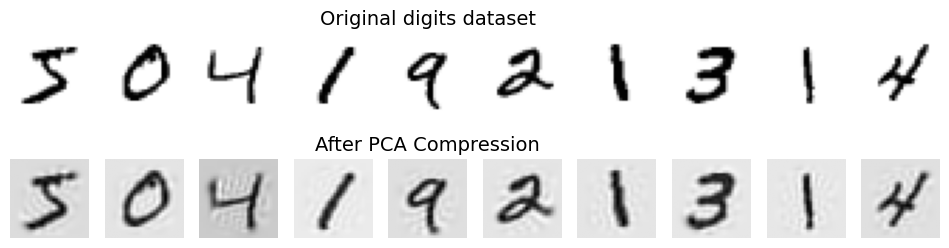

In [ ]:
fig, axes = plt.subplots(2, 10, figsize=(12, 3))

for i in range(10):
    # Original digits (top row)
    axes[0, i].imshow(X_train[i].reshape(28, 28), cmap="binary")
    axes[0, i].axis("off")
    if i == 4:
        axes[0, i].set_title("Original digits dataset")

    # Recovered digits (bottom row)
    axes[1, i].imshow(X_recovered[i].reshape(28, 28), cmap="binary")
    axes[1, i].axis("off")
    if i == 4:
        axes[1, i].set_title("After PCA Compression")

plt.show()


Great question 👍 These two topics — **Randomized PCA** and **Incremental PCA** — are just extensions of standard PCA, designed to solve two different **practical problems**: **speed** and **memory limits**. Let’s break them down in a simple way:

---

## 🔹 1. Randomized PCA (speed problem)

* **Standard PCA** (using SVD) is powerful but **slow** when:

  * The dataset has **many features** (large `n`).
  * Or you only want a **few components** (`d`) compared to `n`.

* **Randomized PCA idea**:

  * Instead of computing *all* principal components exactly, it uses a **stochastic (randomized) algorithm** to approximate just the top `d` components.
  * Complexity:

    * Full SVD: **O(m × n²) + O(n³)**
    * Randomized PCA: **O(m × d²) + O(d³)** (much faster when `d << n`)

👉 In practice:
If you only need, say, the **top 50 components** from a dataset with 10,000 features, Randomized PCA is **dramatically faster** with almost no accuracy loss.

✅ Example:

```python
from sklearn.decomposition import PCA

rnd_pca = PCA(n_components=154, svd_solver="randomized")
X_reduced = rnd_pca.fit_transform(X_train)
```

---

## 🔹 2. Incremental PCA (memory problem)

* **Standard PCA** also has a **memory issue**:
  It needs the **entire dataset in memory** at once to compute SVD.

* If your dataset is huge (e.g., millions of rows, like full MNIST or ImageNet), this becomes impossible.

* **Incremental PCA idea**:

  * Split the dataset into **mini-batches**.
  * Call `partial_fit()` on each batch → PCA learns incrementally.
  * At the end, you can still reduce dimensionality as usual.

👉 In practice:
This allows PCA on datasets that are **too large to fit in RAM**.

✅ Example:

```python
from sklearn.decomposition import IncrementalPCA
import numpy as np

n_batches = 100
inc_pca = IncrementalPCA(n_components=154)

for X_batch in np.array_split(X_train, n_batches):
    inc_pca.partial_fit(X_batch)

X_reduced = inc_pca.transform(X_train)
```

---

## ✨ Key Differences

| Feature      | Randomized PCA                            | Incremental PCA                   |
| ------------ | ----------------------------------------- | --------------------------------- |
| Solves       | **Speed** problem                         | **Memory** problem                |
| Works by     | Approximate PCs using randomness          | Processes dataset in **chunks**   |
| When to use? | Data fits in memory but too many features | Dataset too big to fit in memory  |
| Accuracy     | Approximation (very close to exact)       | Exact (just incremental learning) |

---

📌 **Intuition**:

* **Randomized PCA** is like saying: *"I don’t need exact answers for all directions, just quickly show me the top few important ones."*
* **Incremental PCA** is like saying: *"I can’t load the whole dataset at once, so I’ll look at it batch by batch and slowly build the full picture."*

---




# Randomized PCA

In [ ]:
rnd_pca=PCA(n_components=154, svd_solver="randomized", random_state=42)
X_reduced=rnd_pca.fit_transform(X_train)

# Incremental PCA

Incremental PCA

In [ ]:
from sklearn.decomposition import IncrementalPCA
n_batches=100
inc_pca=IncrementalPCA(n_components=154)
for X_batch in np.array_split(X_train, n_batches):
  inc_pca.fit(X_batch)
  X_reduced=inc_pca.transform(X_train)

# **Memoray_Map**

In [ ]:
filename="my_mnist.map"
X_mmap=np.memmap(filename, dtype="float32", mode="write", shape=X_train.shape)
X_mmap[:]=X_train
X_mmap.flush()

🔹 In plain words

First you save your dataset on disk using memmap.

Later, you reload it in read-only mode and train PCA batch by batch, without ever loading the whole dataset into RAM.

This is super useful for big data + online learning.

In [ ]:
X_mmap=np.memmap(filename, dtype="float32", mode="readonly", shape=X_train.shape)
batch_size=X_mmap.shape[0]//n_batches
inc_pca=IncrementalPCA(n_components=154, batch_size=batch_size)
inc_pca.fit(X_mmap)


IncrementalPCA(batch_size=600, n_components=154)

# Kernal PCA

Great question 👍 You’ve now entered **Kernel PCA (kPCA)**, which is an extension of PCA but with the **kernel trick**. Let’s break it down step by step so it’s easy to digest.

---

## 🔹 1. Normal PCA Recap

* PCA works by finding directions (principal components) in the data that explain the **maximum variance**.
* It projects data **linearly** into a lower-dimensional space.
* Works well if the data is roughly spread out along linear axes.

But what if your data lies on a **curved surface (manifold)** like the **Swiss Roll** dataset?
👉 Linear PCA can’t “unroll” it.

---

## 🔹 2. Enter Kernel Trick

* The **kernel trick** maps data into a higher-dimensional space (without actually computing the mapping).
* In this new space, complex structures may become **linearly separable** or easier to project.

⚡ Example:

* Imagine trying to flatten a Swiss roll.
* In the original 3D space → it looks twisted.
* With the right kernel, kPCA can project it into **2D unrolled form**, where clusters are clear.

---

## 🔹 3. How Kernel PCA Works

* Instead of computing covariance in the original feature space, it uses a **kernel function** (like RBF, polynomial, or sigmoid) to measure similarity between points.
* This allows **nonlinear PCA**.
* The choice of kernel defines how the data will be "seen" in higher space.

---

## 🔹 4. Scikit-Learn Code Explanation

```python
from sklearn.decomposition import KernelPCA

# kPCA with Radial Basis Function (Gaussian) kernel
rbf_pca = KernelPCA(n_components=2, kernel="rbf", gamma=0.04)
X_reduced = rbf_pca.fit_transform(X)
```

* `n_components=2` → reduce to 2D for visualization.
* `kernel="rbf"` → Radial Basis Function (Gaussian), good for nonlinear structures.
* `gamma=0.04` → controls the width of the RBF kernel (small gamma = wider influence, large gamma = localized influence).
* `fit_transform(X)` → applies kPCA to dataset `X`.

---

## 🔹 5. Results (like Figure 8-10 in your book)

* **Linear Kernel (regular PCA)** → Projects but doesn’t unroll Swiss Roll.
* **RBF Kernel** → Successfully unrolls the Swiss Roll into a flat 2D plane.
* **Sigmoid Kernel** → Another nonlinear transformation, but works differently (like logistic activation).

---

## 🔹 6. Intuition (Plain Words)

* PCA = "straight-line projection" → good for flat, linear data.
* kPCA = "curved projection" → good for twisted, nonlinear data.
* Kernels are like **lenses**:

  * Linear lens = straight flattening.
  * RBF lens = flexible bending, good for complex shapes.
  * Sigmoid lens = S-shaped distortions.

---

✅ In summary:

* **Theory**: kPCA = PCA + kernel trick → handles nonlinear structures.
* **Code**: Same as PCA, just add `kernel="rbf"` (or other kernels).
* **Output**: More meaningful low-dimensional representations, especially when data lies on a **nonlinear manifold**.

---



In [ ]:
from sklearn.decomposition import KernelPCA
from sklearn.datasets import make_swiss_roll

X_swiss, t = make_swiss_roll(n_samples=1000, noise=0.1, random_state=42)

rbf_pca=KernelPCA(n_components=2,
                  kernel="rbf", gamma=0.04)
X_reduced = rbf_pca.fit_transform(X_swiss)

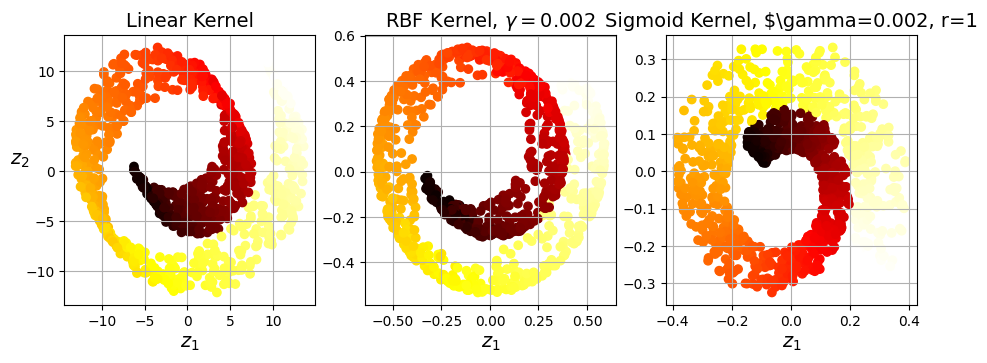

In [ ]:
from sklearn.decomposition import KernelPCA
import matplotlib.pyplot as plt

lin_pca=KernelPCA(
    kernel="linear"
)
rbf_pca=KernelPCA(
    kernel="rbf",
    gamma=0.002
)
sig_pca=KernelPCA(
    kernel='sigmoid',
    gamma=0.002,
    coef0=1
)
kernel_pcas=[(lin_pca, "Linear Kernel"),

             (rbf_pca,rf"RBF Kernel, $\gamma={rbf_pca.gamma}$"),
             (sig_pca, rf"Sigmoid Kernel, $\gamma={sig_pca.gamma}, r={sig_pca.coef0}")]

plt.figure(figsize=(11, 3.5))
for idx, (kpca, title) in enumerate(kernel_pcas):
  kpca.n_components=2
  kpca.random_state=42
  X_reduced=kpca.fit_transform(X_swiss)
  plt.subplot(1, 3, idx+1)
  plt.title(title)
  plt.scatter(X_reduced[:, 0], X_reduced[:, 1], c=t, cmap=plt.cm.hot)
  plt.xlabel("$z_1$")
  if idx == 0:
    plt.ylabel("$z_2$", rotation=0)
  plt.grid()

plt.show()

# Selecting Hyperparameters

In [ ]:
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import GridSearchCV
from sklearn.decomposition import KernelPCA
import numpy as np

clf=Pipeline([

              ("Kpca", KernelPCA(n_components=2)),
              ("log_reg", LogisticRegression())
])

param_grid=[{
    "kpca__gamma":np.linspace(0.03, 0.05, 10),
    "kpca__kernel":["rbf", "sigmoid"]
}]

grid_search=GridSearchCV(clf, param_grid, cv=3)
grid_search.fit(X, y)

print(grid_search.best_params_)

In [ ]:
from sklearn.decomposition import KernelPCA
from sklearn.metrics import mean_squared_error

rbf_pca = KernelPCA(
    n_components=2, kernel="rbf", gamma=0.0433,
    fit_inverse_transform=True   # 🔥 enables inverse_transform()
)
X_reduced = rbf_pca.fit_transform(X)
X_preimage = rbf_pca.inverse_transform(X_reduced)

print(mean_squared_error(X, X_preimage))
# Example output: 32.78


1.1304921142463547


Perfect 👌 You’re now in the **advanced part of Kernel PCA (kPCA)** → **kernel selection and hyperparameter tuning**. Let’s break it into **theory + code** so it becomes super clear.

---

# 🔹 1. The Problem

* In **PCA**, we can measure **reconstruction error** easily: compress → decompress → compare with original.
* In **kPCA**, things are trickier:

  * Data is mapped into an **infinite-dimensional feature space** (via kernel trick).
  * Linear PCA happens in that feature space.
  * If we try to **reconstruct** the original data, the result lives in that infinite-dimensional space → not in the original feature space.
  * So we cannot directly compute reconstruction error.

---

# 🔹 2. Two Ways to Select Kernel & Parameters

### ✅ Approach A: **Supervised (with labels)**

* If kPCA is a preprocessing step before classification (e.g., logistic regression), just use **GridSearchCV**:

  ```python
  clf = Pipeline([
      ("kpca", KernelPCA(n_components=2)),
      ("log_reg", LogisticRegression())
  ])

  param_grid = [{
      "kpca__gamma": np.linspace(0.03, 0.05, 10),
      "kpca__kernel": ["rbf", "sigmoid"]
  }]

  grid_search = GridSearchCV(clf, param_grid, cv=3)
  grid_search.fit(X, y)

  print(grid_search.best_params_)
  ```
* It searches for the kernel + gamma that give the **best classification accuracy** after dimensionality reduction.
  👉 Simple, practical, works if you have labels.

---

### ✅ Approach B: **Unsupervised (no labels)**

* We want to minimize **reconstruction error** → how well compressed data can be brought back.
* Since exact reconstruction is impossible, we use the **reconstruction pre-image**:

  * Find the point in the original input space that is “closest” to the mapped point in feature space.
  * Compare that to the original input.

👉 In Scikit-Learn:

```python
from sklearn.decomposition import KernelPCA
from sklearn.metrics import mean_squared_error

rbf_pca = KernelPCA(
    n_components=2, kernel="rbf", gamma=0.0433,
    fit_inverse_transform=True   # 🔥 enables inverse_transform()
)
X_reduced = rbf_pca.fit_transform(X)
X_preimage = rbf_pca.inverse_transform(X_reduced)

print(mean_squared_error(X, X_preimage))
# Example output: 32.78
```

* `fit_inverse_transform=True` → makes Scikit-Learn automatically train a regression model to approximate the inverse mapping.
* `inverse_transform()` → gives you the reconstruction pre-image.
* `mean_squared_error(X, X_preimage)` → measures reconstruction error.
* Lower error = better kernel/hyperparameters.

👉 You can then use **GridSearchCV** again, but this time scoring based on reconstruction error instead of accuracy.

---

# 🔹 3. Intuition in Plain Words

* **Supervised way**:
  “Pick the kernel & gamma that help my downstream task (classification/regression) the most.”

* **Unsupervised way**:
  “Pick the kernel & gamma that let me compress & reconstruct the data with minimal distortion.”

* **Why pre-image?**
  Because kPCA lives in infinite dimensions → we approximate the “reverse mapping” to compare with original data.

---

# 🔹 4. Analogy

Think of **compressing a music file** 🎵:

* PCA = compress → decompress → compare → easy.
* kPCA = compress into a "magical space" where sound waves are distorted. When decompressing, you don’t get the exact original but an approximation. You then measure **how close the reconstructed sound is**.

---

✅ So the **key takeaway**:

* If you have labels → use GridSearchCV with accuracy.
* If no labels → use reconstruction pre-image error.
* `fit_inverse_transform=True` is essential for this.

---


# Locally Linear Embeding

Great question 👍 You’re moving into **Locally Linear Embedding (LLE)**, which is a **Manifold Learning** technique (different from PCA/kPCA). Let’s break this down step by step so you understand both the **theory** and **code**.

---

# 🔹 1. What LLE is About

* Many datasets (like the **Swiss roll**) lie on a **manifold** → a lower-dimensional “surface” embedded in higher dimensions.
* PCA looks for **global linear projections** → not good when the manifold is curved.
* **LLE instead looks locally**:

  * Each point is reconstructed from a **linear combination of its nearest neighbors**.
  * Then it tries to find a low-dimensional representation that preserves these same local relationships.

👉 So the idea is:
“If I can write each point as a weighted sum of its neighbors in high-dim space, I should be able to do the same in low-dim space.”

---

# 🔹 2. Two Main Steps in LLE

### **Step 1 – Compute Weights (W)**

For each training point $x^{(i)}$:

* Find its **k nearest neighbors**.
* Compute weights $w_{i,j}$ such that:

  $$
  x^{(i)} \approx \sum_{j=1}^{m} w_{i,j} \, x^{(j)}
  $$

  (only neighbors have nonzero weights).
* Constraint: $\sum_j w_{i,j} = 1$.
  👉 This step captures **local geometry**.

---

### **Step 2 – Find Low-Dim Embedding (Z)**

Now, map each point $x^{(i)}$ to a low-dim point $z^{(i)}$ (say 2D).

* Keep weights fixed.
* Optimize so that:

  $$
  z^{(i)} \approx \sum_{j=1}^{m} w_{i,j} \, z^{(j)}
  $$
* This ensures that **the same local relationships** hold in the lower-dimensional space.

👉 This step gives you the **reduced dataset**.

---

# 🔹 3. Code Example

```python
from sklearn.manifold import LocallyLinearEmbedding
import matplotlib.pyplot as plt
from sklearn.datasets import make_swiss_roll

# 1. Create Swiss roll dataset
X, t = make_swiss_roll(n_samples=1000, noise=0.2, random_state=42)

# 2. Apply LLE
lle = LocallyLinearEmbedding(n_components=2, n_neighbors=10)
X_reduced = lle.fit_transform(X)

# 3. Plot
plt.figure(figsize=(12, 5))

# Original 3D
ax = plt.subplot(121, projection="3d")
ax.scatter(X[:, 0], X[:, 1], X[:, 2], c=t, cmap=plt.cm.Spectral)
ax.set_title("Original Swiss Roll (3D)")

# Reduced 2D
plt.subplot(122)
plt.scatter(X_reduced[:, 0], X_reduced[:, 1], c=t, cmap=plt.cm.Spectral)
plt.title("Swiss Roll Unrolled by LLE (2D)")

plt.show()
```

✅ Output:

* Left: Curved Swiss roll in 3D.
* Right: Flat 2D “unrolled” version → LLE successfully reveals the intrinsic structure.

---

# 🔹 4. Key Insights

* LLE preserves **local geometry**, not global distances.

  * That’s why in Figure 8-12, the left side of the roll looks stretched while the right side looks squeezed.
* It works amazingly well for **manifold data** (like Swiss roll).
* But, it doesn’t scale well to **very large datasets** (because of the $O(m^2)$ cost in step 2).

---

# 🔹 5. Analogy

Imagine flattening a **rolled-up carpet**:

* PCA would try to flatten it **straight down**, losing shape.
* LLE carefully looks at **how nearby threads are related**, then tries to flatten while keeping those local relationships intact.

---


Great question 👍 You’re moving into **Locally Linear Embedding (LLE)**, which is a **Manifold Learning** technique (different from PCA/kPCA). Let’s break this down step by step so you understand both the **theory** and **code**.

---

# 🔹 1. What LLE is About

* Many datasets (like the **Swiss roll**) lie on a **manifold** → a lower-dimensional “surface” embedded in higher dimensions.
* PCA looks for **global linear projections** → not good when the manifold is curved.
* **LLE instead looks locally**:

  * Each point is reconstructed from a **linear combination of its nearest neighbors**.
  * Then it tries to find a low-dimensional representation that preserves these same local relationships.

👉 So the idea is:
“If I can write each point as a weighted sum of its neighbors in high-dim space, I should be able to do the same in low-dim space.”

---

# 🔹 2. Two Main Steps in LLE

### **Step 1 – Compute Weights (W)**

For each training point $x^{(i)}$:

* Find its **k nearest neighbors**.
* Compute weights $w_{i,j}$ such that:

  $$
  x^{(i)} \approx \sum_{j=1}^{m} w_{i,j} \, x^{(j)}
  $$

  (only neighbors have nonzero weights).
* Constraint: $\sum_j w_{i,j} = 1$.
  👉 This step captures **local geometry**.

---

### **Step 2 – Find Low-Dim Embedding (Z)**

Now, map each point $x^{(i)}$ to a low-dim point $z^{(i)}$ (say 2D).

* Keep weights fixed.
* Optimize so that:

  $$
  z^{(i)} \approx \sum_{j=1}^{m} w_{i,j} \, z^{(j)}
  $$
* This ensures that **the same local relationships** hold in the lower-dimensional space.

👉 This step gives you the **reduced dataset**.

---

# 🔹 3. Code Example

```python
from sklearn.manifold import LocallyLinearEmbedding
import matplotlib.pyplot as plt
from sklearn.datasets import make_swiss_roll

# 1. Create Swiss roll dataset
X, t = make_swiss_roll(n_samples=1000, noise=0.2, random_state=42)

# 2. Apply LLE
lle = LocallyLinearEmbedding(n_components=2, n_neighbors=10)
X_reduced = lle.fit_transform(X)

# 3. Plot
plt.figure(figsize=(12, 5))

# Original 3D
ax = plt.subplot(121, projection="3d")
ax.scatter(X[:, 0], X[:, 1], X[:, 2], c=t, cmap=plt.cm.Spectral)
ax.set_title("Original Swiss Roll (3D)")

# Reduced 2D
plt.subplot(122)
plt.scatter(X_reduced[:, 0], X_reduced[:, 1], c=t, cmap=plt.cm.Spectral)
plt.title("Swiss Roll Unrolled by LLE (2D)")

plt.show()
```

✅ Output:

* Left: Curved Swiss roll in 3D.
* Right: Flat 2D “unrolled” version → LLE successfully reveals the intrinsic structure.

---

# 🔹 4. Key Insights

* LLE preserves **local geometry**, not global distances.

  * That’s why in Figure 8-12, the left side of the roll looks stretched while the right side looks squeezed.
* It works amazingly well for **manifold data** (like Swiss roll).
* But, it doesn’t scale well to **very large datasets** (because of the $O(m^2)$ cost in step 2).

---

# 🔹 5. Analogy

Imagine flattening a **rolled-up carpet**:

* PCA would try to flatten it **straight down**, losing shape.
* LLE carefully looks at **how nearby threads are related**, then tries to flatten while keeping those local relationships intact.

---

|

In [ ]:
from sklearn.datasets import make_swiss_roll
from sklearn.manifold import LocallyLinearEmbedding
X_swiss, t=make_swiss_roll(n_samples=1000, noise=0.2, random_state=41)
lle=LocallyLinearEmbedding(n_components=2, n_neighbors=10, random_state=42)
X_unrolled=lle.fit_transform(X_swiss)

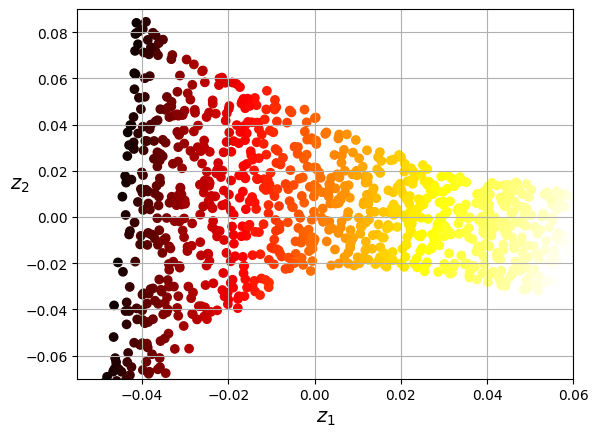

In [ ]:
plt.scatter(
    X_unrolled[:, 0],
    X_unrolled[:, 1],
    c=t,
    cmap=plt.cm.hot

)
plt.xlabel("$z_1$")
plt.ylabel("$z_2$", rotation=0)
plt.axis([-0.055, 0.060, -0.070, 0.090])
plt.grid(True)
plt.show()

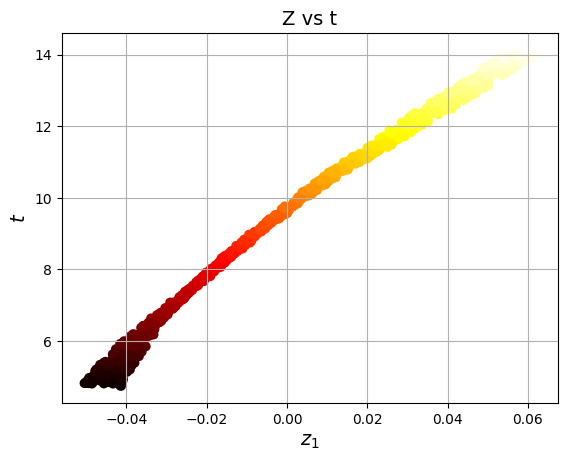

In [ ]:
plt.title("Z vs t")
plt.scatter(X_unrolled[:, 0],t, c=t, cmap=plt.cm.hot)
plt.xlabel("$z_1$")
plt.ylabel("$t$")
plt.grid(True)
plt.show()


# **Other Techniques**

Great question 👍
Dimensionality reduction techniques can be overwhelming at first because they all seem to “compress data.”
But the real difference is **their purpose** → what they try to preserve in the low-dimensional space.

Let’s break each one down simply:

---

### 🔹 1. **Multidimensional Scaling (MDS)**

* **Where/Why used:**
  When you care about **preserving pairwise distances** between data points.
  Example: If two cities are 100 km apart, after dimensionality reduction they should still feel \~100 km apart in the reduced space.
* **Purpose:** Best for **visualization** of data similarity in fewer dimensions.

---

### 🔹 2. **Isomap**

* **Where/Why used:**
  For data lying on a **curved manifold** (like the Swiss roll example).
  Instead of straight-line distance (Euclidean), it preserves **geodesic distances** (distance following the curve/surface).
* **Purpose:** Good at **“unrolling” curved manifolds** where global structure matters.

---

### 🔹 3. **t-SNE (t-Distributed Stochastic Neighbor Embedding)**

* **Where/Why used:**
  Mostly for **visualization of high-dimensional data** (like word embeddings or MNIST digits).
  Preserves **local clusters** → points that are similar stay close, dissimilar ones are far apart.
* **Purpose:** Best when you want to **see clusters or groups** in complex high-dimensional data.
  ⚠️ Not good for scaling to huge datasets or for general preprocessing (mainly visualization).

---

### 🔹 4. **Linear Discriminant Analysis (LDA)**

* **Where/Why used:**
  Used when you have **labeled data (classification)**.
  Finds axes that maximize the **separation between classes**.
* **Purpose:** Best as a **preprocessing step before classifiers** (SVM, logistic regression, etc.), because it reduces dimensionality while keeping classes as distinguishable as possible.

---

✅ **Summary Table:**

| Technique  | Preserves                      | Good for                            | Unsupervised / Supervised |
| ---------- | ------------------------------ | ----------------------------------- | ------------------------- |
| **MDS**    | Distances (Euclidean)          | Visualization of similarities       | Unsupervised              |
| **Isomap** | Geodesic distances             | Manifold learning (curved surfaces) | Unsupervised              |
| **t-SNE**  | Local neighborhoods (clusters) | Visualization of clusters in 2D/3D  | Unsupervised              |
| **LDA**    | Class separation               | Preprocessing for classification    | Supervised                |

---

👉 Rule of thumb:

* If you want **visualization** → use **t-SNE** or **MDS**.
* If data lies on a **curved manifold** → use **Isomap** or **LLE**.
* If doing **classification with labels** → use **LDA** before your classifier.

---



In [ ]:
from sklearn.manifold import MDS
mds=MDS(n_components=2, normalized_stress=False, random_state=42)
X_reduced_mds=mds.fit_transform(X_swiss)

In [ ]:
from sklearn.manifold import Isomap
isomap=Isomap(n_components=2)
X_reduced_isomap=isomap.fit_transform(X_swiss)

In [ ]:
from sklearn .manifold import TSNE
tsne=TSNE(n_components=2,
          init="random",
          learning_rate="auto",
          random_state=42)
X_reduced_tsne=tsne.fit_transform(X_swiss)

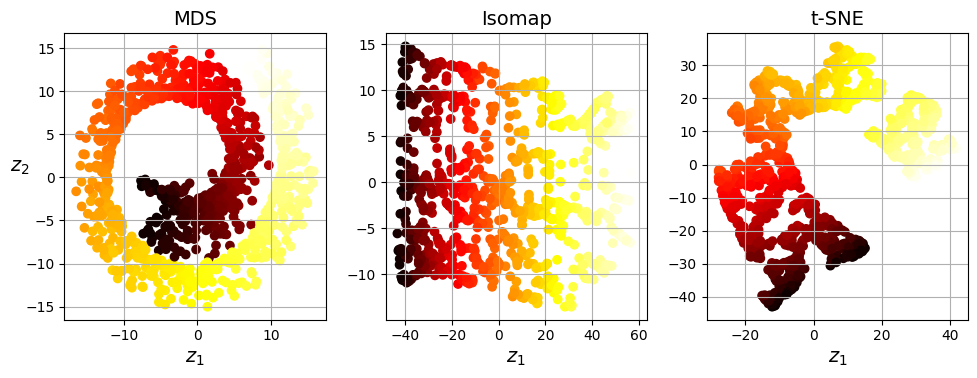

In [ ]:
title=["MDS", "Isomap", "t-SNE"] # Corrected title for MDS and t-SNE
plt.figure(figsize=(10,  4
                    ))
for subplot, plot_title, X_reduced in zip(
    (131, 132, 133), # Corrected subplot codes for a 1x3 grid
    title,
    (X_reduced_mds, X_reduced_isomap, X_reduced_tsne)):
    plt.subplot(subplot)
    plt.title(plot_title) # Use plot_title variable
    plt.scatter(X_reduced[:, 0],X_reduced[:, 1], c=t, cmap=plt.cm.hot ) # Added cmap for coloring and corrected plt.
    plt.xlabel("$z_1$")
    if subplot == 131:
        plt.ylabel("$z_2$", rotation=0)
    plt.grid(True)

save_fig("other_dim_reduction_plot")
plt.show()

# **Exercise**

Exercise**

Question 0.1

Perfect 👌 this is an exam-style question from **Chapter 8 (Dimensionality Reduction)**.
Let’s break it down clearly:

---

## 🎯 **Main Motivations (Why we reduce dimensionality):**

1. **Visualization**

   * We humans can only visualize in 2D or 3D.
   * Dimensionality reduction helps plot **high-dimensional data** in 2D/3D (e.g., visualizing MNIST digits or word embeddings).

2. **Speeding up training**

   * Fewer features → less computation → faster model training and inference.
   * Particularly important for algorithms with high time complexity.

3. **Reducing storage & memory needs**

   * Smaller feature set = less RAM/disk usage.

4. **Removing redundancy**

   * Many features are correlated (e.g., height in cm and inches).
   * Dimensionality reduction compresses such redundancy.

5. **Improving generalization / avoiding the curse of dimensionality**

   * In very high dimensions, data becomes sparse and models overfit.
   * Reducing to fewer, more meaningful dimensions can improve model performance.

---

## ⚠️ **Main Drawbacks (Why it’s risky):**

1. **Information loss**

   * By compressing data, you throw away some variance → may lose important predictive information.

2. **Adds complexity to pipeline**

   * You must train and apply the transformation before modeling.
   * This makes debugging and interpretation harder.

3. **Harder to interpret features**

   * Transformed features (like PCA components) are combinations of original features, so they lose **semantic meaning**.
   * E.g., “component 1” doesn’t directly correspond to a real-world variable like “height.”

4. **May not always improve performance**

   * If the original dataset is already well-structured and not too high-dimensional, reduction can **hurt accuracy** instead of helping.

---

✅ **Quick Mnemonic**:

* **Motivations:** *See better, train faster, store less, generalize more.*
* **Drawbacks:** *Lose info, pipeline complexity, less interpretability, possible worse accuracy.*

---



Great question 👍 this is a **core concept** behind dimensionality reduction.

---

## 🎯 **Curse of Dimensionality (Definition)**

The **curse of dimensionality** refers to the problems that arise when analyzing data in **very high-dimensional spaces** (many features). As the number of dimensions increases, data becomes sparse, distances lose meaning, and models struggle to generalize.

---

## 🔑 **Key Issues in High Dimensions:**

1. **Data sparsity**

   * In high dimensions, points are far apart → huge feature space requires exponentially more data to cover.
   * Example: In 1D, 100 points cover \[0,1] well. In 100D, you’d need astronomically more points to cover the same relative density.

2. **Distance metrics break down**

   * In high dimensions, all points tend to look equally far apart → nearest neighbor ≈ farthest neighbor.
   * This hurts algorithms relying on distance (e.g., KNN, clustering).

3. **Overfitting risk increases**

   * More dimensions → more possible patterns → models can fit noise instead of signal.

4. **Computational cost explodes**

   * Storage, training, and search complexity increase exponentially with dimensions.

---

## ⚖️ **Example:**

* Imagine you want to sample enough points in a 1D line of length 10. Just 10 points (one per unit) is fine.
* But in 10D space (a cube of side 10), to have the same density, you’d need $10^{10}$ points — impossible!

---

✅ **Exam-ready 2–3 line answer:**
The curse of dimensionality refers to the difficulties that arise in high-dimensional spaces: data becomes sparse, distances lose meaning, models require exponentially more data, and overfitting is more likely. This makes learning harder and motivates dimensionality reduction.

---



# Question  no.3

Great exam-style question ⚡ Let’s answer it step by step.

---

## ✅ **Is it possible to reverse dimensionality reduction?**

👉 **In general: No (not exactly).**

* When you reduce dimensionality (e.g., PCA, LLE, t-SNE), you **throw away information**.
* This information loss means you cannot perfectly reconstruct the original dataset.

---

## 🔄 **But sometimes partial reversal is possible:**

1. **Linear PCA (with all components kept):**

   * If you keep *all* principal components, PCA is just a rotation of the data → you can reverse it exactly.
   * If you keep fewer components, you can only approximate the original data using the **inverse transform**, but details are lost.

2. **Kernel PCA (with `fit_inverse_transform=True` in Scikit-Learn):**

   * You can compute an approximate reconstruction, called the **pre-image**.
   * This gives you a point in the original space that is “close” to the original, but not exact.

3. **Other nonlinear methods (e.g., LLE, t-SNE, Isomap):**

   * These are not easily invertible.
   * You can try supervised regression or neural networks to approximate the inverse, but it won’t be perfect.

---

## ⚠️ **Why not exactly reversible?**

* **Information loss:** Dropping dimensions = discarding variance/features.
* **Many-to-one mapping:** Multiple original points may collapse to the same reduced representation.

---

## 🎯 **Exam-ready 4–5 line answer:**

Once dimensionality is reduced, the operation cannot generally be reversed exactly because information is lost (many features are discarded). However, some methods like PCA allow an approximate reconstruction using the inverse transform, and Kernel PCA can compute a pre-image. Nonlinear methods like LLE or t-SNE are not naturally reversible.

---




 # Question n0.4

Good one 👌 — this is exactly the kind of tricky theory question examiners love.

---

## ✅ **Answer:**

* **PCA is a linear method.**
  It works by finding directions (principal components) that maximize variance, but these are always **linear combinations** of the original features.

* On a **highly nonlinear dataset** (e.g., Swiss roll, concentric circles):

  * Standard PCA will fail to capture the nonlinear structure.
  * It might project the data in a way that looks like overlapping blobs, losing the underlying manifold.

* **Solution:** Use **Kernel PCA (kPCA)** or other nonlinear dimensionality reduction techniques (LLE, Isomap, t-SNE).

  * These methods apply the **kernel trick** or **manifold learning** to capture the nonlinear relationships.
  * For example, kPCA with an RBF kernel can “unwrap” a Swiss roll into a nice 2D sheet, which plain PCA cannot do.

---

## 🎯 **Exam-ready short answer:**

No — standard PCA cannot properly reduce the dimensionality of a highly nonlinear dataset because it only captures **linear structures**. For nonlinear manifolds, techniques like **Kernel PCA, LLE, or t-SNE** should be used instead.

---



# Question n0.5

Nice — this is a **conceptual PCA question** where the answer depends on the dataset. Let’s unpack it carefully 👇

---

### ✅ Step-by-step reasoning:

* PCA works by sorting the principal components by how much variance they explain.
* The **explained variance ratio** tells us how much of the dataset’s variance is captured by each component.
* If you set it to **95%**, PCA will **keep only the minimum number of dimensions (components)** needed to explain at least **95% of the variance**.

---

### ⚠️ Important:

* You started with a **1,000-dimensional dataset**.
* After PCA with `explained_variance_ratio = 0.95`, you will end up with **d dimensions**, where:

  $$
  d < 1000 \quad \text{and just enough so that cumulative variance ≥ 95%}
  $$
* The **exact number of dimensions (d)** depends entirely on the dataset — could be 50, 120, 300, etc.
* So the answer is: **not fixed**.

---

### 🎯 **Exam-ready Answer:**

After PCA with 95% explained variance, the dataset will be reduced to **the smallest number of dimensions needed to preserve 95% of the variance**. This number will be **less than 1,000**, but the exact value depends on the dataset’s structure.

---




# **QUestion n0.6**

Great exam-style question! Let’s break it down clearly 👇

---

## 🎯 **When to Use Each PCA Variant**

### 1. **Vanilla PCA (Standard PCA)**

* **Use when:**

  * Dataset fits easily in memory.
  * You want **exact** principal components.
  * Data size is **not huge** (moderate number of samples/features).
* **Example:** MNIST dataset (60,000 × 784) can still be handled.

---

### 2. **Incremental PCA (IPCA)**

* **Use when:**

  * Dataset is **too large to fit in memory at once**.
  * You want to process data in **mini-batches** or **streaming data**.
* **Example:** Training on a **massive dataset** stored on disk (millions of rows).
* **Key idea:** Uses `.partial_fit()` batch by batch.

---

### 3. **Randomized PCA**

* **Use when:**

  * You need a **fast approximation** of PCA.
  * Number of features is **very large** (high-dimensional data).
  * You don’t need 100% exact precision, just a **good approximation**.
* **Example:** Text data with **tens of thousands of features** (like TF–IDF vectors).
* **Key idea:** Much faster complexity → $O(m \cdot d^2)$ instead of $O(m \cdot n^2)$.

---

### 4. **Kernel PCA (kPCA)**

* **Use when:**

  * Data has a **nonlinear structure** (not well captured by linear PCA).
  * You want to **unroll manifolds** (like Swiss roll).
  * Useful for **manifold learning**, visualization, or preprocessing before classification.
* **Example:** Nonlinear datasets like Swiss roll, concentric circles.
* **Key idea:** Uses kernel trick (e.g., RBF kernel) to project data into higher-dimensional feature space.

---

## ✅ Quick Summary Table

| **PCA Type**        | **When to Use**                          | **Pros**                    | **Cons**                               |
| ------------------- | ---------------------------------------- | --------------------------- | -------------------------------------- |
| **Vanilla PCA**     | Small/medium datasets, exact solution    | Accurate                    | Needs all data in memory               |
| **Incremental PCA** | Huge datasets, streaming/online learning | Handles large data          | Slightly slower, approximate           |
| **Randomized PCA**  | High-dimensional data, need speed        | Very fast                   | Approximate only                       |
| **Kernel PCA**      | Nonlinear data, manifolds                | Captures nonlinear patterns | Harder to scale, tuning kernels needed |

---

👉 Mnemonic:

* **Vanilla = normal**
* **Incremental = big data**
* **Randomized = speed**
* **Kernel = nonlinear**

---




# Question .no7

Great question 👍 Let’s go step by step.

When you use a **dimensionality reduction algorithm**, your goal is usually to **compress the dataset while keeping as much useful information as possible**. To evaluate how well it worked, you can use the following approaches:

---

### **1. Explained Variance Ratio (for PCA and linear methods)**

* Check how much of the original variance is preserved.
* Example: if your PCA with 50 components explains **95% of the variance**, that means your reduced dataset keeps almost all the important information.

✅ Use when you want a **quick measure** of retained information.

---

### **2. Reconstruction Error**

* Try to reconstruct the original data from the reduced dimensions (e.g., using PCA inverse transform).
* Compute the difference between the original and reconstructed data:

  $$
  \text{Reconstruction Error} = ||X - \hat{X}||^2
  $$
* A small error means the algorithm preserved most of the information.

✅ Use when you want to **check how much detail is lost**.

---

### **3. Downstream Task Performance**

* Train a model (e.g., classifier, regressor) on both:

  * the original dataset
  * the reduced dataset
* Compare performance (accuracy, F1-score, RMSE, etc.).
* If the reduced dataset gives similar performance → good reduction.

✅ Use when your goal is to **speed up ML training/testing**.

---

### **4. Visualization (for 2D or 3D reductions)**

* Reduce data to 2D or 3D and plot it.
* Check if clusters, patterns, or class separations are preserved.

✅ Useful for **exploratory data analysis**.

---

👉 So, the main ways:

* **Explained Variance** → how much info is preserved (PCA-like methods).
* **Reconstruction Error** → how close reduced+reconstructed is to original.
* **Model Performance** → does the reduced data still work well for tasks?
* **Visualization** → does it still "look" meaningful?

---




# **Question n0.8**

Yes 👍 — in some situations it **does make sense** to chain two dimensionality reduction algorithms. Let me explain clearly:

---

### ✅ When chaining makes sense

1. **Combining linear + nonlinear methods**

   * Example: First apply **PCA** to reduce from 10,000 → 200 dimensions (removing noise, speeding things up).
   * Then apply **t-SNE, UMAP, or Kernel PCA** on those 200 dimensions to map into 2D/3D for visualization.
   * Why? Nonlinear methods scale badly with very high dimensions, so PCA helps preprocess.

---

2. **Noise filtering + feature extraction**

   * First use PCA (or Randomized PCA) to remove redundant/noisy directions.
   * Then apply another technique like **LDA (Linear Discriminant Analysis)** to maximize class separability.
   * Chaining helps because the first step cleans, the second step extracts meaningful features.

---

3. **Scalability reasons**

   * Some methods (Kernel PCA, Isomap, t-SNE) are too slow on high-dimensional data.
   * Using **Incremental PCA → Kernel PCA** makes training feasible.

---

### ❌ When chaining doesn’t help

* If both methods try to do **the same thing** (e.g., PCA → Randomized PCA → Incremental PCA), you won’t gain anything — just extra computation.
* If the second method already works well directly on the raw data, chaining may only distort information.

---

### 🔑 Rule of Thumb

* **Linear first, nonlinear second** often makes sense.
* **Two nonlinear in a row** rarely adds value.

---

👉 Example workflow in practice:

* **PCA → t-SNE** (very common in ML research for visualization of high-dimensional embeddings).
* **PCA → LDA** (common in face recognition, document classification).

---




#Question .no 09

In [ ]:
from sklearn.datasets import fetch_openml
mnist=fetch_openml("mnist_784",as_frame=False)

In [ ]:
X_train=mnist.data[:60000]
y_train=mnist.target[:60000]
X_test=mnist.data[60000:]
y_test=mnist.target[60000:]

In [ ]:
from sklearn.ensemble import RandomForestClassifier

In [ ]:
rnd_clf=RandomForestClassifier(
    n_estimators=100,
    random_state=42
)

In [ ]:
%time rnd_clf.fit(X_train, y_train)

CPU times: user 1min 2s, sys: 218 ms, total: 1min 2s
Wall time: 1min 11s


RandomForestClassifier(random_state=42)

In [ ]:
from sklearn.metrics import accuracy_score
y_pred=rnd_clf.predict(X_test)
accuracy_score(y_test, y_pred)

0.9705

In [ ]:
from sklearn.decomposition import PCA
pca=PCA(n_components=0.95)
X_reduced=pca.fit_transform(X_train)

In [ ]:
rnd_clf_with_pca=RandomForestClassifier(
    n_estimators=100
    ,
    random_state=42
)

In [ ]:
%time rnd_clf_with_pca.fit(X_reduced, y_train)

CPU times: user 3min 8s, sys: 227 ms, total: 3min 9s
Wall time: 3min 30s


RandomForestClassifier(random_state=42)

In [ ]:
X_test_reduced=pca.transform(X_test)
y_pred=rnd_clf_with_pca.predict(X_test_reduced)
accuracy_score(y_test, y_pred)

0.9488

In [ ]:
from sklearn.linear_model import SGDClassifier
sgd_clf=SGDClassifier(random_state=42)

In [ ]:
%time sgd_clf.fit(X_train, y_train)

CPU times: user 3min 6s, sys: 387 ms, total: 3min 7s
Wall time: 3min 28s


SGDClassifier(random_state=42)

In [ ]:
y_pred=sgd_clf.predict(X_test)
accuracy_score(y_test, y_pred)

0.874

In [ ]:
sgd_clf_with_pca=SGDClassifier(random_state=42)
%time sgd_clf_with_pca.fit(X_reduced, y_train)

CPU times: user 44.1 s, sys: 58.3 ms, total: 44.2 s
Wall time: 52.9 s


SGDClassifier(random_state=42)

In [ ]:
y_pred=sgd_clf_with_pca.predict(X_test_reduced)
accuracy_score(y_test, y_pred)

0.8959

# Questiion n0.10

In [ ]:
X_sample, y_sample=X_train[:50000], y_train[:50000]

In [ ]:
from sklearn.manifold import TSNE
tsne=TSNE(
    n_components=2,
    init="random",
    learning_rate="auto",
    random_state=42

)

%time X_reduced=tsne.fit_transform(X_sample)

CPU times: user 16min 37s, sys: 11.7 s, total: 16min 49s
Wall time: 17min 44s


In [ ]:
import matplotlib.pyplot as plt
import numpy as np



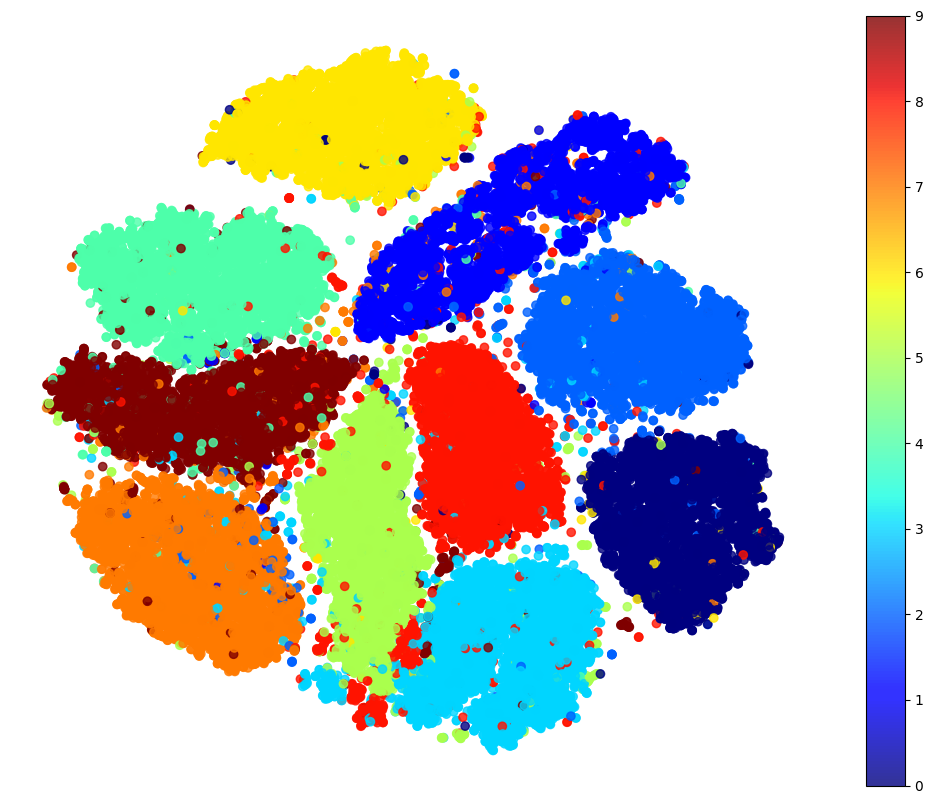

In [ ]:
plt.figure(figsize=(13, 10)

)
plt.scatter(
    X_reduced[:, 0],
    X_reduced[:, 1],
    c=y_sample.astype(np.int8),
    cmap="jet",
    alpha=0.8
)
plt.axis("off")
plt.colorbar()
plt.show()

# Let's Focus on Digit 4 and 9

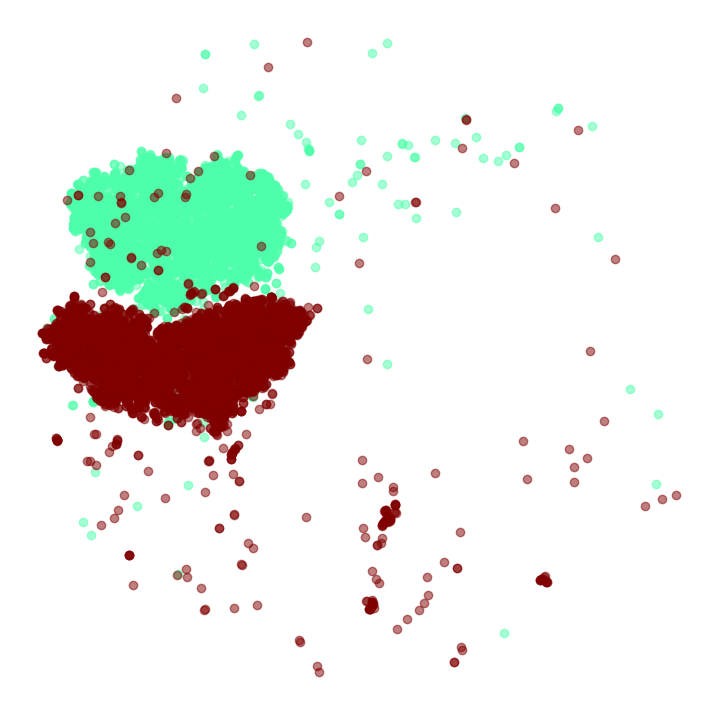

In [ ]:
plt.figure(figsize=(9, 9))
cmap = plt.cm.jet
for digit in ('4', '9'):
    plt.scatter(X_reduced[y_sample == digit, 0], X_reduced[y_sample == digit, 1],
                c=[cmap(float(digit) / 9)], alpha=0.5)
plt.axis('off')
plt.show()

In [ ]:
idx=(y_sample=="4")| (y_sample=="9")
X_subset=X_sample[idx]
y_subset=y_sample[idx]
tsne_subset=TSNE(
    n_components=2,
    init="random",
    learning_rate="auto",
    random_state=42


)
X_subset_reduced=tsne_subset.fit_transform(X_subset)

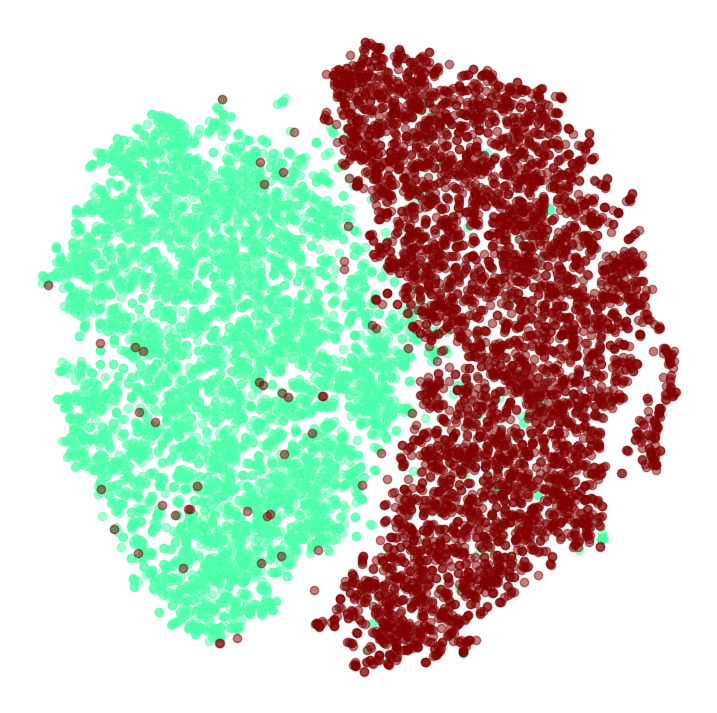

In [ ]:
plt.figure(figsize=(9, 9))
for digit in ('4', '9'):
    plt.scatter(X_subset_reduced[y_subset == digit, 0],
                X_subset_reduced[y_subset == digit, 1],
                c=[cmap(float(digit) / 9)], alpha=0.5)
plt.axis('off')
plt.show()

In [ ]:
from sklearn.preprocessing import MinMaxScaler
from matplotlib.offsetbox import AnnotationBbox, OffsetImage

In [ ]:
def plot_digits(X, y, min_distance=0.04, images=None, figsize=(13, 10)):
    # Let's scale the input features so that they range from 0 to 1
    X_normalized=MinMaxScaler().fit_transform(X)
    plt.figure(figsize=figsize)
    cmap=plt.cm.jet
    digits=np.unique(y)
    for digit in digits:
      plt.scatter(
          X_normalized[y==digit,0],
          X_normalized[y==digit,1],
          c=[cmap(float(digit)/9)],
          alpha=0.5)

    # Initialize neighbors array
    neighbors = np.array([[-1000., -1000.]]) # Initialize with a point far away

    plt.axis("off")
    ax=plt.gca()
    for index,image_coord in enumerate(X_normalized):
      closest_distance=np.linalg.norm(neighbors-image_coord, axis=1).min()
      if closest_distance>min_distance:
        neighbors=np.r_[neighbors, [image_coord]]
        if images is None:
          plt.text(image_coord[0], image_coord[1], str(int(y[index])),
                   color=cmap(float(y[index])/9),
                   fontdict={"weight": "bold", "size": 16})
        else:
          image=images[index].reshape(28,28)
          imagebox=AnnotationBbox(OffsetImage(image, cmap="binary"),
                                   image_coord) # Added image_coord here

          ax.add_artist(imagebox)

In [ ]:
plot_digits(X_reduced, y_subset)

IndexError: boolean index did not match indexed array along axis 0; size of axis is 50000 but size of corresponding boolean axis is 9847

<Figure size 1300x1000 with 0 Axes>

In [ ]:

    ax = plt.gca()  # get current axes
    for index, image_coord in enumerate(X_normalized):
        closest_distance = np.linalg.norm(neighbors - image_coord, axis=1).min()
        if closest_distance > min_distance:
            neighbors = np.r_[neighbors, [image_coord]]
            if images is None:
                plt.text(image_coord[0], image_coord[1], str(int(y[index])),
                         color=cmap(float(y[index]) / 9),
                         fontdict={"weight": "bold", "size": 16})
            else:
                image = images[index].reshape(28, 28)
                imagebox = AnnotationBbox(OffsetImage(image, cmap="binary"),
                                          image_coord)
                ax.add_artist(imagebox)

In [ ]:
plot_digits(X_reduced, y_subset)

IndexError: boolean index did not match indexed array along axis 0; size of axis is 50000 but size of corresponding boolean axis is 9847

<Figure size 1300x1000 with 0 Axes>

In [ ]:
from sklearn.preprocessing import MinMaxScaler
from matplotlib.offsetbox import AnnotationBbox, OffsetImage

def plot_digits(X, y, min_distance=0.04, images=None, figsize=(13, 10)):
    # Let's scale the input features so that they range from 0 to 1
    X_normalized = MinMaxScaler().fit_transform(X)
    # Now we create the list of coordinates of the digits plotted so far.
    # We pretend that one is already plotted far away at the start, to
    # avoid `if` statements in the loop below
    neighbors = np.array([[10., 10.]])
    # The rest should be self-explanatory
    plt.figure(figsize=figsize)
    cmap = plt.cm.jet
    digits = np.unique(y)
    for digit in digits:
        plt.scatter(X_normalized[y == digit, 0], X_normalized[y == digit, 1],
                    c=[cmap(float(digit) / 9)], alpha=0.5)
    plt.axis("off")
    ax = plt.gca()  # get current axes
    for index, image_coord in enumerate(X_normalized):
        closest_distance = np.linalg.norm(neighbors - image_coord, axis=1).min()
        if closest_distance > min_distance:
            neighbors = np.r_[neighbors, [image_coord]]
            if images is None:
                plt.text(image_coord[0], image_coord[1], str(int(y[index])),
                         color=cmap(float(y[index]) / 9),
                         fontdict={"weight": "bold", "size": 16})
            else:
                image = images[index].reshape(28, 28)
                imagebox = AnnotationBbox(OffsetImage(image, cmap="binary"),
                                          image_coord)
                ax.add_artist(imagebox)

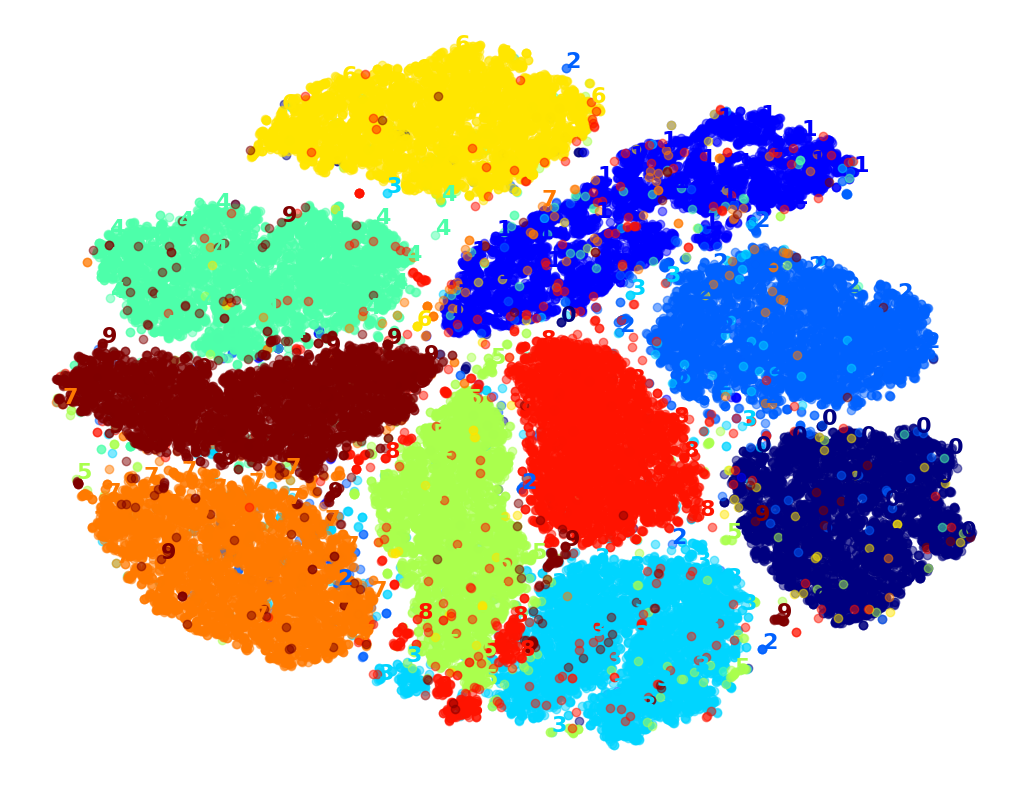

In [ ]:
plot_digits(X_reduced, y_sample)

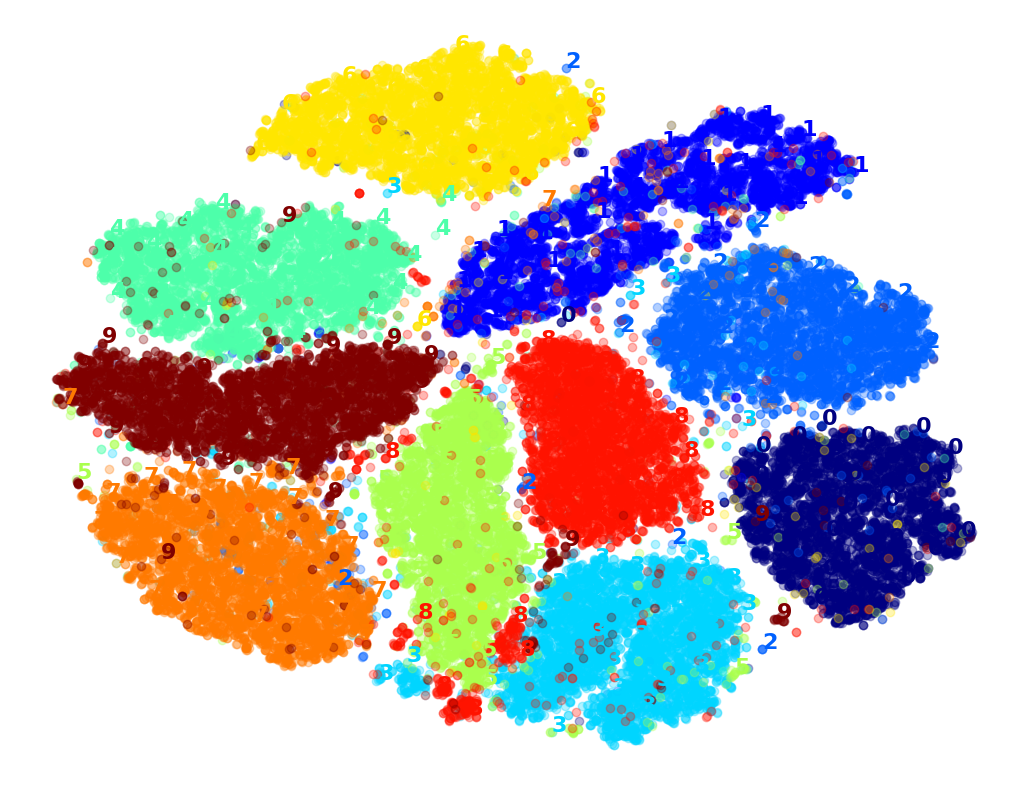

In [ ]:
plot_digits(X_reduced, y_sample)

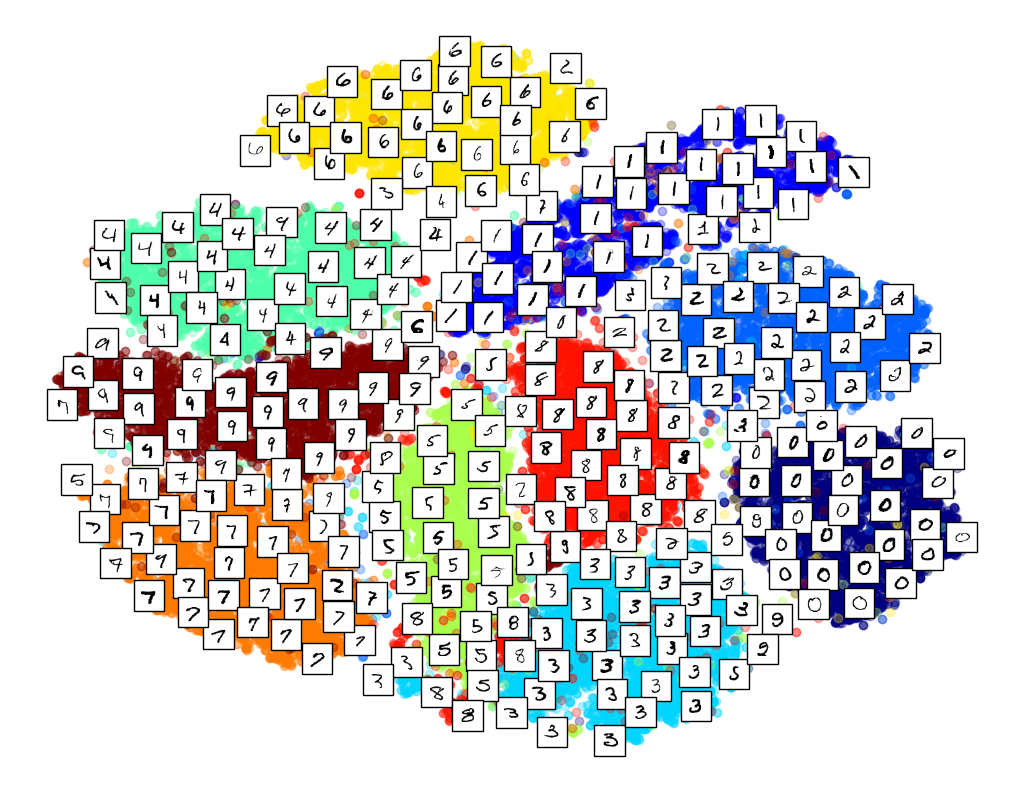

In [ ]:
plot_digits(
    X_reduced,
    y_sample,
    images=X_sample,
    figsize=(13, 10)
)

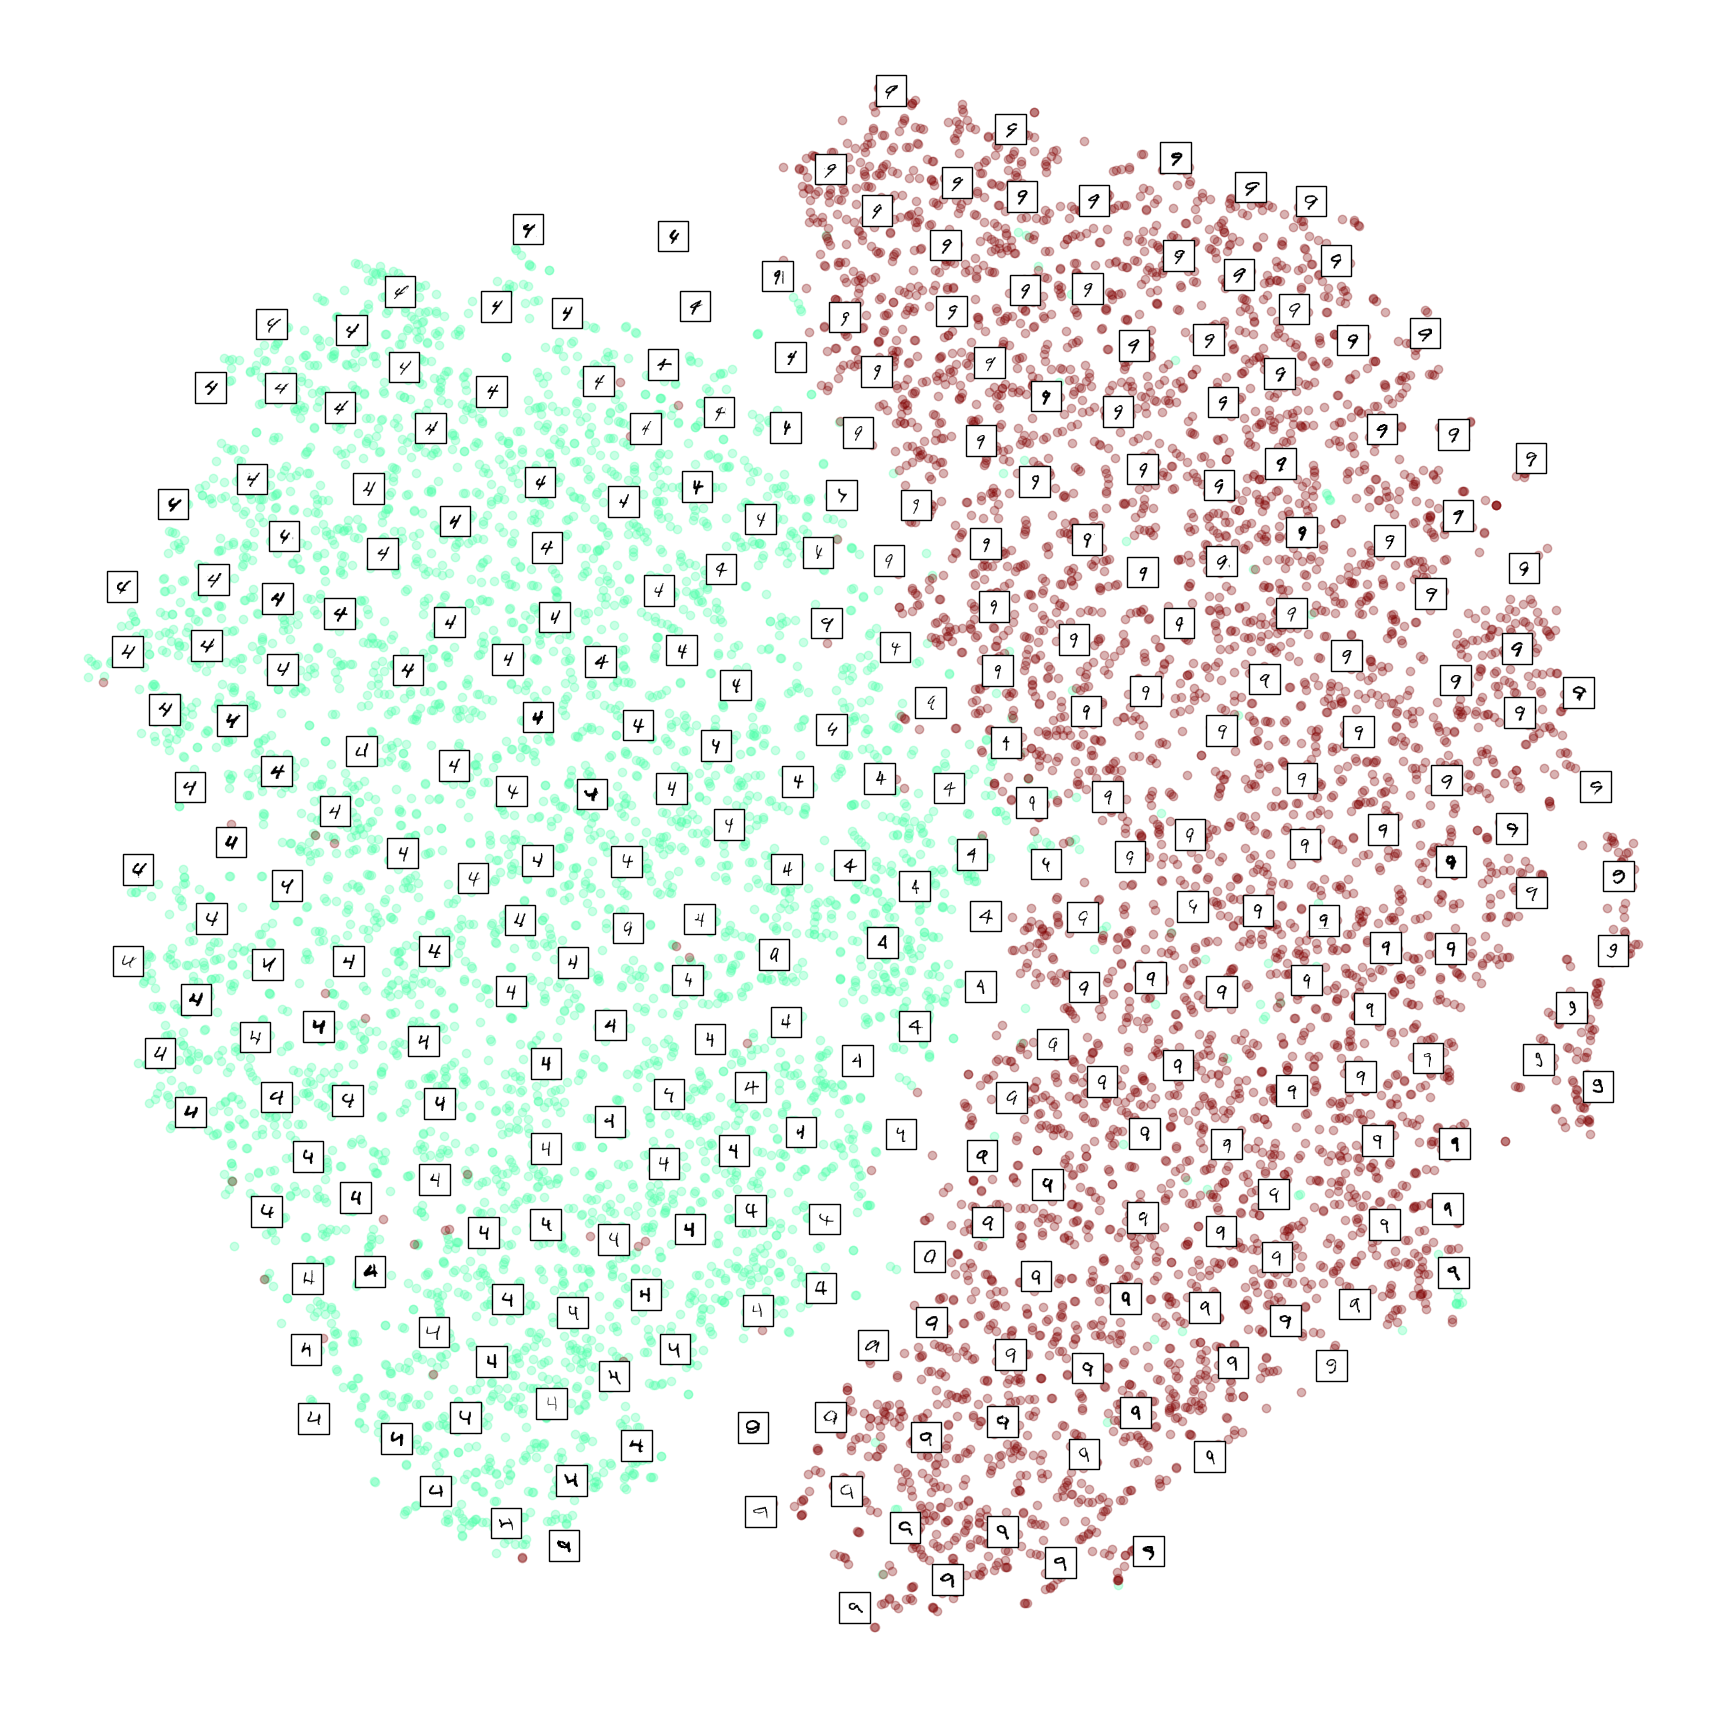

In [ ]:
plot_digits(X_subset_reduced, y_subset, images=X_subset, figsize=(22, 22))

CPU times: user 4.12 s, sys: 617 ms, total: 4.73 s
Wall time: 4.87 s


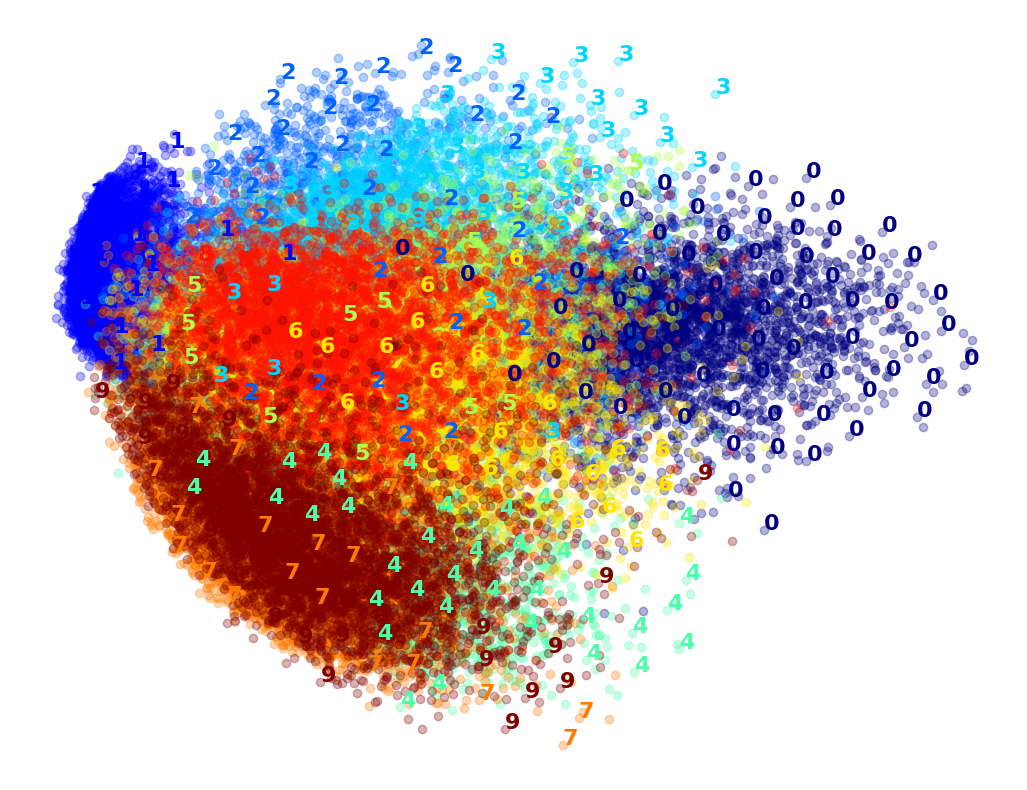

In [ ]:
pca=PCA(n_components=2, random_state=42)
%time X_reduced_pca=pca.fit_transform(X_sample)
plot_digits(X_reduced_pca, y_sample)

In [ ]:
from sklearn .manifold import LocallyLinearEmbedding

In [ ]:
lle=LocallyLinearEmbedding(n_components=2, random_state=42)
%time X_reduced_lle=lle.fit_transform(X_sample)
plot_digits(X_reduced_lle, y_sample)

KeyboardInterrupt: 

NameError: name 'X_reduced_lle' is not defined

# First Pipeline and then  . . . PCA and then  LLE

In [ ]:
from sklearn.pipeline import make_pipeline


In [ ]:
pca_pipeline=make_pipeline(
    PCA(n_components=0.95, random_state=42),
    LocallyLinearEmbedding(n_components=2,random_state=42)



)
%time X_reduced_pca_lle=pca_pipeline.fit_transform(X_sample)
plot_digits(X_reduced_pca_lle, y_sample)

In [ ]:
from sklearn.manifold import  MDS

In [ ]:
%time X_mds_reduced = MDS(n_components=2, normalized_stress=False, random_state=42).fit_transform(X_sample)
plot_digits(X_mds_reduced, y_sample)
plt.show()

In [ ]:
pca_mds = make_pipeline(
    PCA(n_components=0.95, random_state=42),
    MDS(n_components=2, normalized_stress=False, random_state=42)
)

%time X_pca_mds_reduced = pca_mds.fit_transform(X_sample)
plot_digits(X_pca_mds_reduced, y_sample)
plt.show()

In [ ]:
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis

lda = LinearDiscriminantAnalysis(n_components=2)
%time X_lda_reduced = lda.fit_transform(X_sample, y_sample)
plot_digits(X_lda_reduced, y_sample, figsize=(12, 12))
plt.show()